# محاسبه شاخص غنی شدگی بر اساس نقشه های کاربری

In [ ]:
from google.colab import files
uploaded = files.upload()

با وارد کردن کتابخانه های مورد نیاز شروع میکنیم.

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
from osgeo import gdal
import numpy as np
from scipy.ndimage import convolve
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.optimize import curve_fit

در این بلاک کد عکس ها وارد شده اند.

In [ ]:
lu_1380 = gdal.Open("LU_1380.tif")
lu_1390 = gdal.Open("LU_1390.tif")

تصاویر با استفاده از جیدل خوانه شده اند

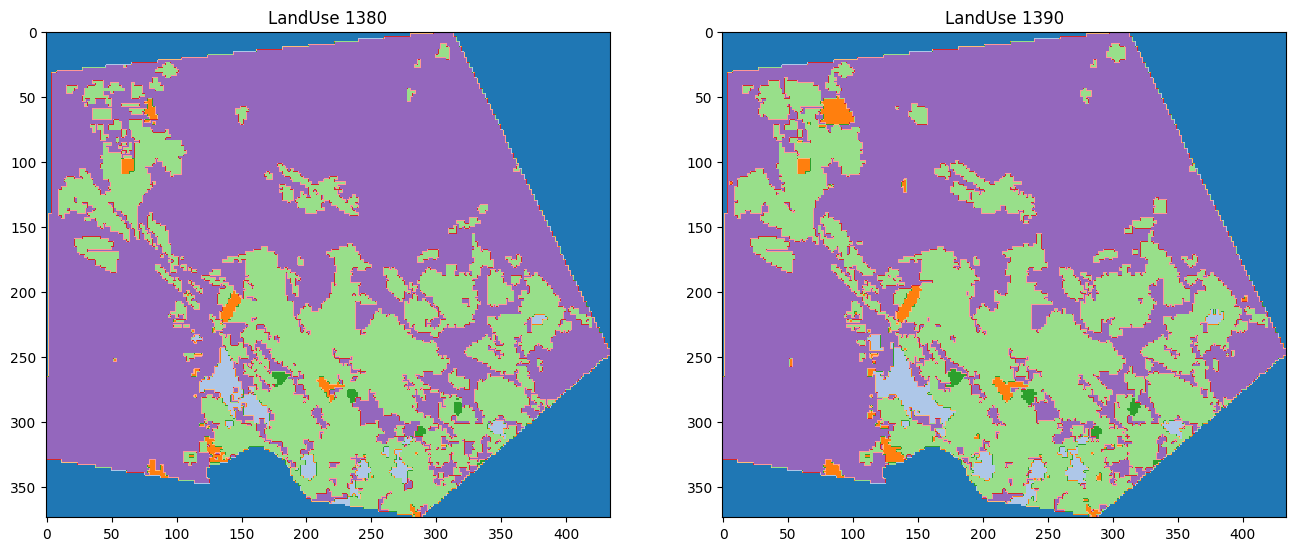

In [ ]:
lu1_data = lu_1380.ReadAsArray().astype(np.uint8)
lu2_data = lu_1390.ReadAsArray().astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(lu1_data, cmap='tab20', vmin=0, vmax=15)
axes[0].set_title('LandUse 1380')

axes[1].imshow(lu2_data, cmap='tab20', vmin=0, vmax=15)
axes[1].set_title('LandUse 1390')

plt.show()

در این مرحله به شمارش تعداد تمامی پیکسل های دو نقشه هم به صورت کلی و هم به صورت تفکیک شده بر اساس نوع کاربری میپردازیم.

In [ ]:
land_use_categories = {
    1: 'Urban',
    2: 'Industrial',
    3: 'Rural',
    4: 'Agricultural',
    6: 'Barren'
}

total_pixels1 = 0
land_use_counts1 = {category: 0 for category in land_use_categories.values()}

total_pixels2 = 0
land_use_counts2 = {category: 0 for category in land_use_categories.values()}

for value, category in land_use_categories.items():
    count = np.count_nonzero(lu1_data == value)
    land_use_counts1[category] = count
    total_pixels1 += count

for value, category in land_use_categories.items():
    count = np.count_nonzero(lu2_data == value)
    land_use_counts2[category] = count
    total_pixels2 += count

تعداد پیکسلهای شمرده شده به صورت زیر میباشد

In [ ]:
df1 = pd.DataFrame.from_dict(land_use_counts1, orient='index', columns=['Count'])
df1.index.name = 'Land Use Category'

df2 = pd.DataFrame.from_dict(land_use_counts2, orient='index', columns=['Count'])
df2.index.name = 'Land Use Category'

df1.loc['Total Pixels'] = total_pixels1
df2.loc['Total Pixels'] = total_pixels2

print("Image 1:")
print(df1)
print("\nImage 2:")
print(df2)

Image 1:
                    Count
Land Use Category        
Urban                1988
Industrial            976
Rural                 272
Agricultural        35500
Barren              85728
Total Pixels       124464

Image 2:
                    Count
Land Use Category        
Urban                2728
Industrial           1692
Rural                 360
Agricultural        39620
Barren              80064
Total Pixels       124464


### جهت پیدا کردن روش مناسب برای تولید نتیجه مطلوب، ابتدا به انجام محاسبات فقط بر روی کاربری شهری تنها در رینگ اول آن میپردازیم

در این بلاک از کد، پیکسلهایی که از هر کاربری دیگری در نقشه سال 1380 به کاربری شهری در نقشه سال 1390 تغییر کرده اند را پیدا میکنیم

In [ ]:
urban_value = 1

changed_to_urban = (lu1_data != lu2_data) & (lu2_data == urban_value)

changed_to_urban_map = np.zeros_like(lu1_data, dtype=np.uint8)
changed_to_urban_map[changed_to_urban] = 1

نقشه زیر نشان دهنده مناطقی است که به کاربری شهری تغییر کاربری داده اند

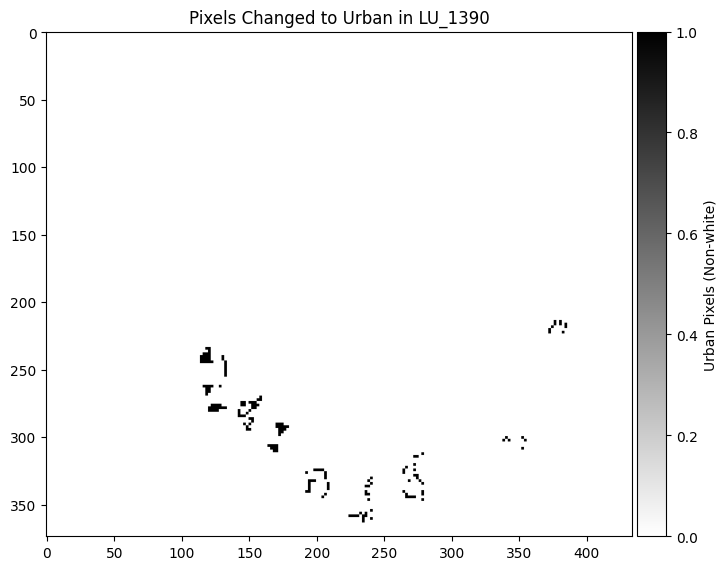

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

im = ax.imshow(changed_to_urban_map, cmap='binary')

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Urban Pixels (Non-white)')

ax.set_title('Pixels Changed to Urban in LU_1390', loc='center')

plt.show()

در این مرحله، هدف شمارش تعداد پیکسلهای شهری موجود در همسایگی 8 تایی (3*3) هر پیکسل مشخص شده در نقشه قبلی میباشد

In [ ]:
def count_urban_neighbors(image, changed_pixels):
    height, width = image.shape
    urban_counts = []

    for i in range(height):
        for j in range(width):
            if changed_pixels[i, j] == 1:
                urban_count = 0

                min_row = max(0, i - 1)
                max_row = min(height - 1, i + 1)
                min_col = max(0, j - 1)
                max_col = min(width - 1, j + 1)

                for row in range(min_row, max_row + 1):
                    for col in range(min_col, max_col + 1):
                        if image[row, col] == 1:
                            urban_count += 1

                urban_counts.append(urban_count)

    return urban_counts

In [ ]:
urban_neighbors_count = count_urban_neighbors(lu2_data, changed_to_urban)

در 3 بلاک بعدی، تراکم محلی و تراکم کلی جداگانه محاسبه شده و بر یکدیگر تقسیم میشوند

In [ ]:
divided_list = [x / 8 for x in urban_neighbors_count]

In [ ]:
divided_list2 = [x / (land_use_counts2['Urban'] / total_pixels2) for x in divided_list]

عدد زیر، نشان دهنده شاخص غنی شدگی در محدوده تعیین شده بر اساس کاربری شهری می باشد

In [ ]:
sum(divided_list2) / len(divided_list2)

41.58495234604132

### اکنون که به پاسخی دست پیدا کردیم که احتمال درست بودن آن وجود دارد، به تکرار همین روند برای همسایگی 5*5 میپردازیم

در تابع زیر مانند تابع مربوط به همسایگی 3*3، این بار تعداد پیکسلهای شهری اطراف پیکسلهای مشخص شده در همسایگی 5_5 آن محاسبه میشود

In [ ]:
def count_urban_neighbors5(image, changed_pixels):
    height, width = image.shape
    urban_counts = []

    for i in range(height):
        for j in range(width):
            if changed_pixels[i, j] == 1:
                urban_count = 0

                min_row = max(0, i - 2)
                max_row = min(height - 1, i + 2)
                min_col = max(0, j - 2)
                max_col = min(width - 1, j + 2)

                inner_min_row = max(0, i - 1)
                inner_max_row = min(height - 1, i + 1)
                inner_min_col = max(0, j - 1)
                inner_max_col = min(width - 1, j + 1)

                for row in range(min_row, max_row + 1):
                    for col in range(min_col, max_col + 1):
                        if (inner_min_row <= row <= inner_max_row) and (inner_min_col <= col <= inner_max_col):
                            continue
                        if image[row, col] == 1:
                            urban_count += 1

                urban_counts.append(urban_count)

    return urban_counts

با تکرار روند قبل برای محاسبه شاخص غنی شدگی، به عدد زیر برای رینگ پنجم کاربری شهری دست پیدا میکنیم.

In [ ]:
urban_neighbors_count5 = count_urban_neighbors5(lu2_data, changed_to_urban)
divided_list5 = [x / 8 for x in urban_neighbors_count5]
divided_list25 = [x / (land_use_counts2['Urban'] / total_pixels2) for x in urban_neighbors_count5]
sum(divided_list25) / len(divided_list25)

464.0957336108248

### حال به اعمال این فرایند بر روی هر 8 رینگ اطراف هر پیکسل شهری می پردازیم. هدف تولید نمودار مربوط به شاخص غنی شدگی شهری-شهری میباشد

تابع زیر بر اساس منطقی مشابه توابع قبلی، همسایگی 8 رینگ اطراف هر پیکسل را مشخص کرده و تعداد پیکسلهای شهری موجود در آنها را شمرده و در یک دیکشنری بر اساس رینگ مربوطه ذخیره میکند

In [ ]:
def count_uu(image, changed_pixels):
    height, width = image.shape
    urban_counts_by_size = {}

    neighborhood_sizes = [3, 5, 7, 9, 11, 13, 15, 17]

    for size in neighborhood_sizes:
        half_size = size // 2
        inner_size = size - 2
        urban_counts = []

        for i in range(height):
            for j in range(width):
                if changed_pixels[i, j] == 1:
                    urban_count = 0

                    min_row = max(0, i - half_size)
                    max_row = min(height - 1, i + half_size)
                    min_col = max(0, j - half_size)
                    max_col = min(width - 1, j + half_size)

                    inner_min_row = max(0, i - inner_size // 2)
                    inner_max_row = min(height - 1, i + inner_size // 2)
                    inner_min_col = max(0, j - inner_size // 2)
                    inner_max_col = min(width - 1, j + inner_size // 2)

                    for row in range(min_row, max_row + 1):
                        for col in range(min_col, max_col + 1):
                            if (inner_min_row <= row <= inner_max_row) and (inner_min_col <= col <= inner_max_col):
                                continue
                            if image[row, col] == 1:
                                urban_count += 1

                    urban_counts.append(urban_count)

        urban_counts_by_size[size] = urban_counts

    return urban_counts_by_size

In [ ]:
uu_f = count_uu(lu2_data, changed_to_urban)

پس از محاسبه تعداد تعداد پیکسلهای شهری در همسایگی هر پیکسل دچار تغییر کاربری شده، به محاسبه شاخص غنی شدگی هر پیکسل میپردازیم.

In [ ]:
average_counts_by_size = {}
for size, counts in uu_f.items():
    inner_size = size - 2
    neighborhood_pixels = size ** 2
    inner_pixels = inner_size ** 2

    average_counts_by_size[size] = [count / (neighborhood_pixels - inner_pixels) for count in counts]

urban_ratio = land_use_counts2['Urban'] / total_pixels2

for size, counts in average_counts_by_size.items():
    average_counts_by_size[size] = [count / urban_ratio for count in counts]

for size, average_counts in average_counts_by_size.items():
    print(f"Normalized average counts for {size}x{size} neighborhood: {average_counts}")

Normalized average counts for 3x3 neighborhood: [17.10923753665689, 17.10923753665689, 17.10923753665689, 17.10923753665689, 28.515395894428153, 28.515395894428153, 28.515395894428153, 28.515395894428153, 28.515395894428153, 28.515395894428153, 28.515395894428153, 28.515395894428153, 17.10923753665689, 17.10923753665689, 34.21847507331378, 34.21847507331378, 34.21847507331378, 34.21847507331378, 34.21847507331378, 28.515395894428153, 17.10923753665689, 34.21847507331378, 39.921554252199414, 28.515395894428153, 34.21847507331378, 45.624633431085044, 45.624633431085044, 28.515395894428153, 17.10923753665689, 34.21847507331378, 28.515395894428153, 45.624633431085044, 28.515395894428153, 45.624633431085044, 45.624633431085044, 34.21847507331378, 17.10923753665689, 34.21847507331378, 34.21847507331378, 17.10923753665689, 28.515395894428153, 28.515395894428153, 28.515395894428153, 17.10923753665689, 45.624633431085044, 45.624633431085044, 45.624633431085044, 28.515395894428153, 45.6246334310

سپس از تمامی مقادیر تولید شده به تفکیک رینگها، میانگین گرفته میشود تا برای هر رینگ، عددی واحد در دست باشد

In [ ]:
average_of_averages = {}
for size, counts in average_counts_by_size.items():
    average_of_averages[size] = sum(counts) / len(counts)

for size, average in average_of_averages.items():
    print(f"Average of all values for {size}x{size} neighborhood: {average}")

Average of all values for 3x3 neighborhood: 35.881873167155646
Average of all values for 5x5 neighborhood: 29.00598335067655
Average of all values for 7x7 neighborhood: 26.259204624286717
Average of all values for 9x9 neighborhood: 23.701506479992585
Average of all values for 11x11 neighborhood: 21.033937186642703
Average of all values for 13x13 neighborhood: 18.580999905401615
Average of all values for 15x15 neighborhood: 16.850803073097556
Average of all values for 17x17 neighborhood: 15.277200004730002


نمودارهای زیر نشان دهنده شاخص غنی شدگی و لوگاریتم این شاخص برای کاربری شهری-شهری میباشد.

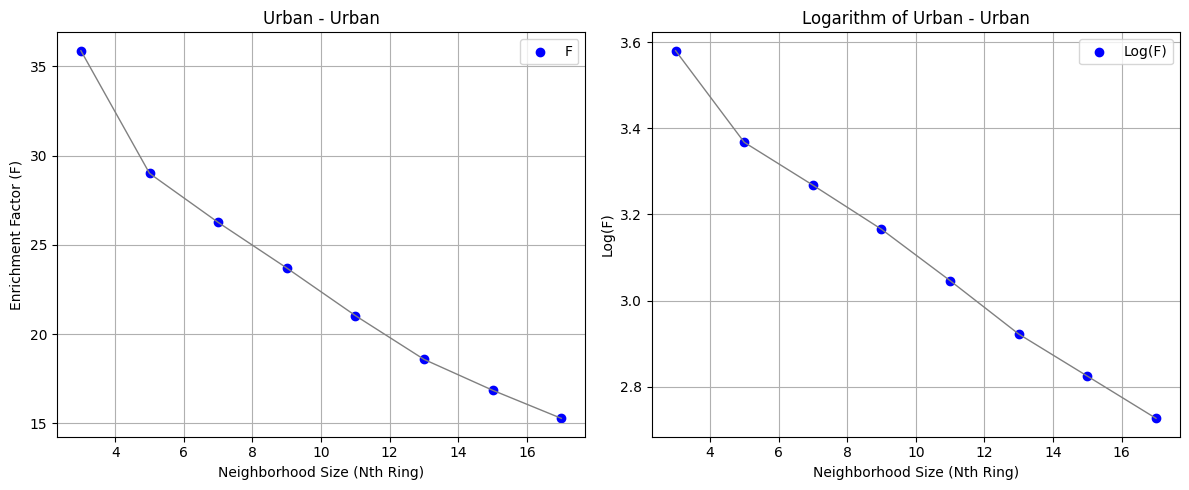

In [ ]:
neighborhood_sizes = list(average_of_averages.keys())
averages = list(average_of_averages.values())

log_averages = np.log(averages)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].scatter(neighborhood_sizes, averages, color='blue', label='F')
axs[0].plot(neighborhood_sizes, averages, color='gray', linestyle='-', linewidth=1)
axs[0].set_xlabel('Neighborhood Size (Nth Ring)')
axs[0].set_ylabel('Enrichment Factor (F)')
axs[0].set_title('Urban - Urban')
axs[0].legend()
axs[0].grid(True)

axs[1].scatter(neighborhood_sizes, log_averages, color='blue', label='Log(F)')
axs[1].plot(neighborhood_sizes, log_averages, color='gray', linestyle='-', linewidth=1)
axs[1].set_xlabel('Neighborhood Size (Nth Ring)')
axs[1].set_ylabel('Log(F)')
axs[1].set_title('Logarithm of Urban - Urban')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

## Moving on to the other land use categories using the same method.

## حال که تا حدی از جواب دهی روش ارائه شده اطمینان داریم، به اعمال همین روند برای تمامی کاربریها میپردازیم

تابع زیر تعریف شده است تا بر اساس دو نقشه ای که به آن داده میشود، و مقدار پیکسلی که بیانگر نوع کاربری است، پیکسلهایی را که به آن کاربری تغییر کرده اند را پیدا کند

In [ ]:
def change_detector(lu1, lu2, lu_value):
    changed = (lu1 != lu2) & (lu2 == lu_value)
    changed_map = np.zeros_like(lu1, dtype=np.uint8)
    changed_map[changed] = 1
    return changed_map

در بلاک کد زیر، به ترتیب پیکسلهای تغییر پیدا کرده به شهری، صنعتی، روستایی و کشاورزی استخراج شده اند

In [ ]:
changed_to_urban = change_detector(lu1_data, lu2_data, 1)
changed_to_industrial = change_detector(lu1_data, lu2_data, 2)
changed_to_rural = change_detector(lu1_data, lu2_data, 3)
changed_to_agricultural = change_detector(lu1_data, lu2_data, 4)

نقشه این پیکسلهای تغییر پیدا کرده به تفکیک کاربری به صورت زیر میباشد

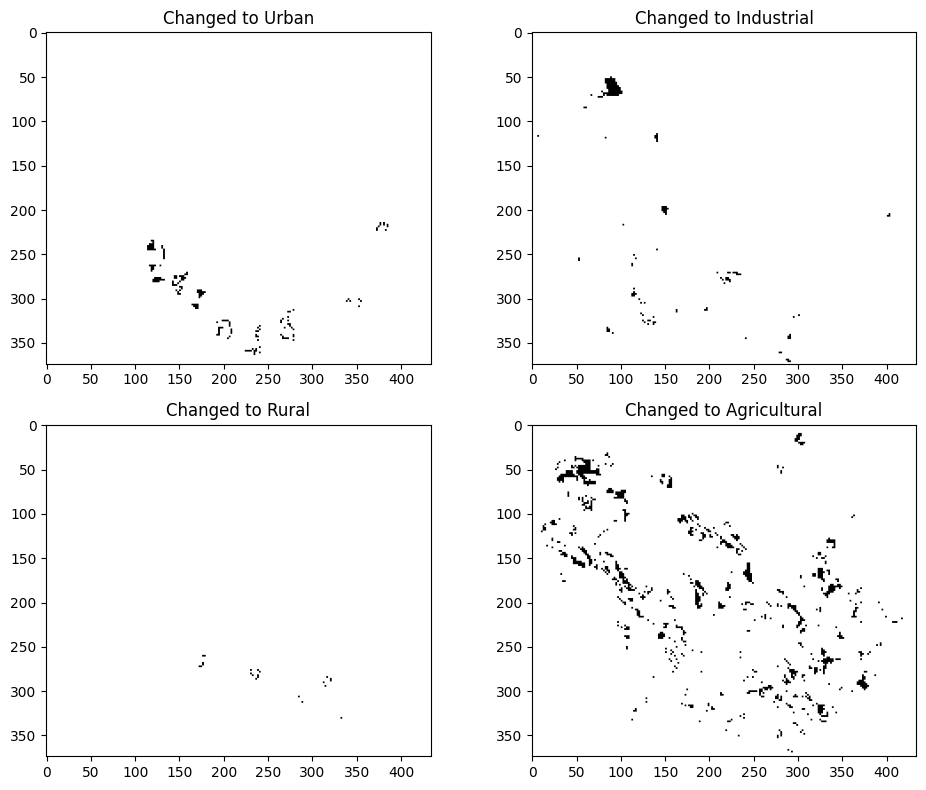

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

axs[0, 0].imshow(changed_to_urban, cmap='binary')
axs[0, 0].set_title('Changed to Urban')

axs[0, 1].imshow(changed_to_industrial, cmap='binary')
axs[0, 1].set_title('Changed to Industrial')

axs[1, 0].imshow(changed_to_rural, cmap='binary')
axs[1, 0].set_title('Changed to Rural')

axs[1, 1].imshow(changed_to_agricultural, cmap='binary')
axs[1, 1].set_title('Changed to Agricultural')

plt.tight_layout()
plt.show()

## **Rectangular Neighborhood**

### اکنون به سراغ اعمال همسایگی مربعی دارای 8 رینگ بر روی تمامی کاربری ها میرویم

تابع زیر به صورتی نوشته شده است که نقشه اصلی و  نقشه پیکسلهای تغییر کاربری پیدا کرده را بگیرد. علاوه بر این، مقدار پیکسل آن کاربری که قرار است تعداد پیکسلهایش در همسایگی مشخص شده شمرده شود را نیز دریافت میکند

In [ ]:
def count_neighborhood_rec(image, changed_pixels, lu_value):
    height, width = image.shape
    lu_counts_by_size = {}

    neighborhood_sizes = [3, 5, 7, 9, 11, 13, 15, 17]

    for size in neighborhood_sizes:
        half_size = size // 2
        inner_size = size - 2
        lu_counts = []

        for i in range(height):
            for j in range(width):
                if changed_pixels[i, j] == 1:
                    lu_count = 0

                    min_row = max(0, i - half_size)
                    max_row = min(height - 1, i + half_size)
                    min_col = max(0, j - half_size)
                    max_col = min(width - 1, j + half_size)

                    inner_min_row = max(0, i - inner_size // 2)
                    inner_max_row = min(height - 1, i + inner_size // 2)
                    inner_min_col = max(0, j - inner_size // 2)
                    inner_max_col = min(width - 1, j + inner_size // 2)

                    for row in range(min_row, max_row + 1):
                        for col in range(min_col, max_col + 1):
                            if (inner_min_row <= row <= inner_max_row) and (inner_min_col <= col <= inner_max_col):
                                continue
                            if image[row, col] == lu_value:
                                lu_count += 1

                    lu_counts.append(lu_count)

        lu_counts_by_size[size] = lu_counts

    return lu_counts_by_size

تابع تعریف شده برای هر 16 حالت اثرگذاری کاربریها بر یکدیگر محاسبه میشود

In [ ]:
uu_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_urban, 1)
ui_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_urban, 2)
ur_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_urban, 3)
ua_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_urban, 4)

iu_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_industrial, 1)
ii_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_industrial, 2)
ir_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_industrial, 3)
ia_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_industrial, 4)

ru_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_rural, 1)
ri_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_rural, 2)
rr_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_rural, 3)
ra_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_rural, 4)

au_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_agricultural, 1)
ai_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_agricultural, 2)
ar_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_agricultural, 3)
aa_neighbors_rec = count_neighborhood_rec(lu2_data, changed_to_agricultural, 4)

تابع دیگری جهت محاسبه شاخص غنی شدگی (تراکم محلی و تراکم کلی) به صورت زیر نوشته میشود. این تابع، پیکسلهای شمرده شده در همسایگی با استفاده از تابع قبلی را دریافت میکند. در کنار آن، تعداد کل پیکسلهای کاربری مورد بررسی در نقشه و تعداد کل پیکسلهای موجود در این نقشه نیز به تابع داده میشوند

In [ ]:
def enrichment_factor(lu_neighbors_count, lu_counts, land_use, total_pixels):
    local_f = {}

    #Local F
    for size, counts in lu_neighbors_count.items():
        inner_size = size - 2
        neighborhood_pixels = size ** 2
        inner_pixels = inner_size ** 2

        local_f[size] = [count / (neighborhood_pixels - inner_pixels) for count in counts]

    #Global F
    global_f = lu_counts[land_use] / total_pixels\

    #Enrichment Factor
    for size, counts in local_f.items():
        local_f[size] = [count / global_f for count in counts]

    #Average of the Enrichment Factors for every pixel corresponding the same neighborhood
    enrichment_f = {}
    for size, counts in local_f.items():
        enrichment_f[size] = sum(counts) / len(counts)

    return enrichment_f

In [ ]:
uu_enrich_f = enrichment_factor(uu_neighbors_rec, land_use_counts2, 'Urban', total_pixels2)
ui_enrich_f = enrichment_factor(ui_neighbors_rec, land_use_counts2, 'Urban', total_pixels2)
ur_enrich_f = enrichment_factor(ur_neighbors_rec, land_use_counts2, 'Urban', total_pixels2)
ua_enrich_f = enrichment_factor(ua_neighbors_rec, land_use_counts2, 'Urban', total_pixels2)

iu_enrich_f = enrichment_factor(iu_neighbors_rec, land_use_counts2, 'Industrial', total_pixels2)
ii_enrich_f = enrichment_factor(ii_neighbors_rec, land_use_counts2, 'Industrial', total_pixels2)
ir_enrich_f = enrichment_factor(ir_neighbors_rec, land_use_counts2, 'Industrial', total_pixels2)
ia_enrich_f = enrichment_factor(ia_neighbors_rec, land_use_counts2, 'Industrial', total_pixels2)

ru_enrich_f = enrichment_factor(ru_neighbors_rec, land_use_counts2, 'Rural', total_pixels2)
ri_enrich_f = enrichment_factor(ri_neighbors_rec, land_use_counts2, 'Rural', total_pixels2)
rr_enrich_f = enrichment_factor(rr_neighbors_rec, land_use_counts2, 'Rural', total_pixels2)
ra_enrich_f = enrichment_factor(ra_neighbors_rec, land_use_counts2, 'Rural', total_pixels2)

au_enrich_f = enrichment_factor(au_neighbors_rec, land_use_counts2, 'Agricultural', total_pixels2)
ai_enrich_f = enrichment_factor(ai_neighbors_rec, land_use_counts2, 'Agricultural', total_pixels2)
ar_enrich_f = enrichment_factor(ar_neighbors_rec, land_use_counts2, 'Agricultural', total_pixels2)
aa_enrich_f = enrichment_factor(aa_neighbors_rec, land_use_counts2, 'Agricultural', total_pixels2)

به کمک تابع زیر، نمودارها کنار یکدیگر نمایش داده میشوند

In [ ]:
def plot_enrichment_factor(enrich_f_dict, title):
    all_x_values = [value for values in enrich_f_dict.values() for value in values.keys() if not np.isnan(value) and not np.isinf(value)]
    all_y_values = [value for values in enrich_f_dict.values() for value in values.values() if not np.isnan(value) and not np.isinf(value)]
    min_x = min(all_x_values)
    max_x = max(all_x_values)
    min_y = min(all_y_values)
    max_y = max(all_y_values)

    fig, axs = plt.subplots(4, 4, figsize=(20, 20))

    for i, (key, values) in enumerate(enrich_f_dict.items()):
        row = i // 4
        col = i % 4

        x_values = list(values.keys())
        y_values = list(values.values())

        axs[row, col].scatter(x_values, y_values)
        axs[row, col].plot(x_values, y_values, linestyle='-', color='blue')
        axs[row, col].set_title(key)
        axs[row, col].set_xlabel('Neighborhood Window Size')
        axs[row, col].set_ylabel('Enrichment Factor')
        axs[row, col].set_xlim([min_x, max_x])
        axs[row, col].set_ylim([min_y, max_y])
        axs[row, col].grid(True)


    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

نمودارهای زیر نشان دهنده شاخص غنی شدگی برای هر 16 حالت اثرگذاری کاربری ها بر یکدیگر میباشند



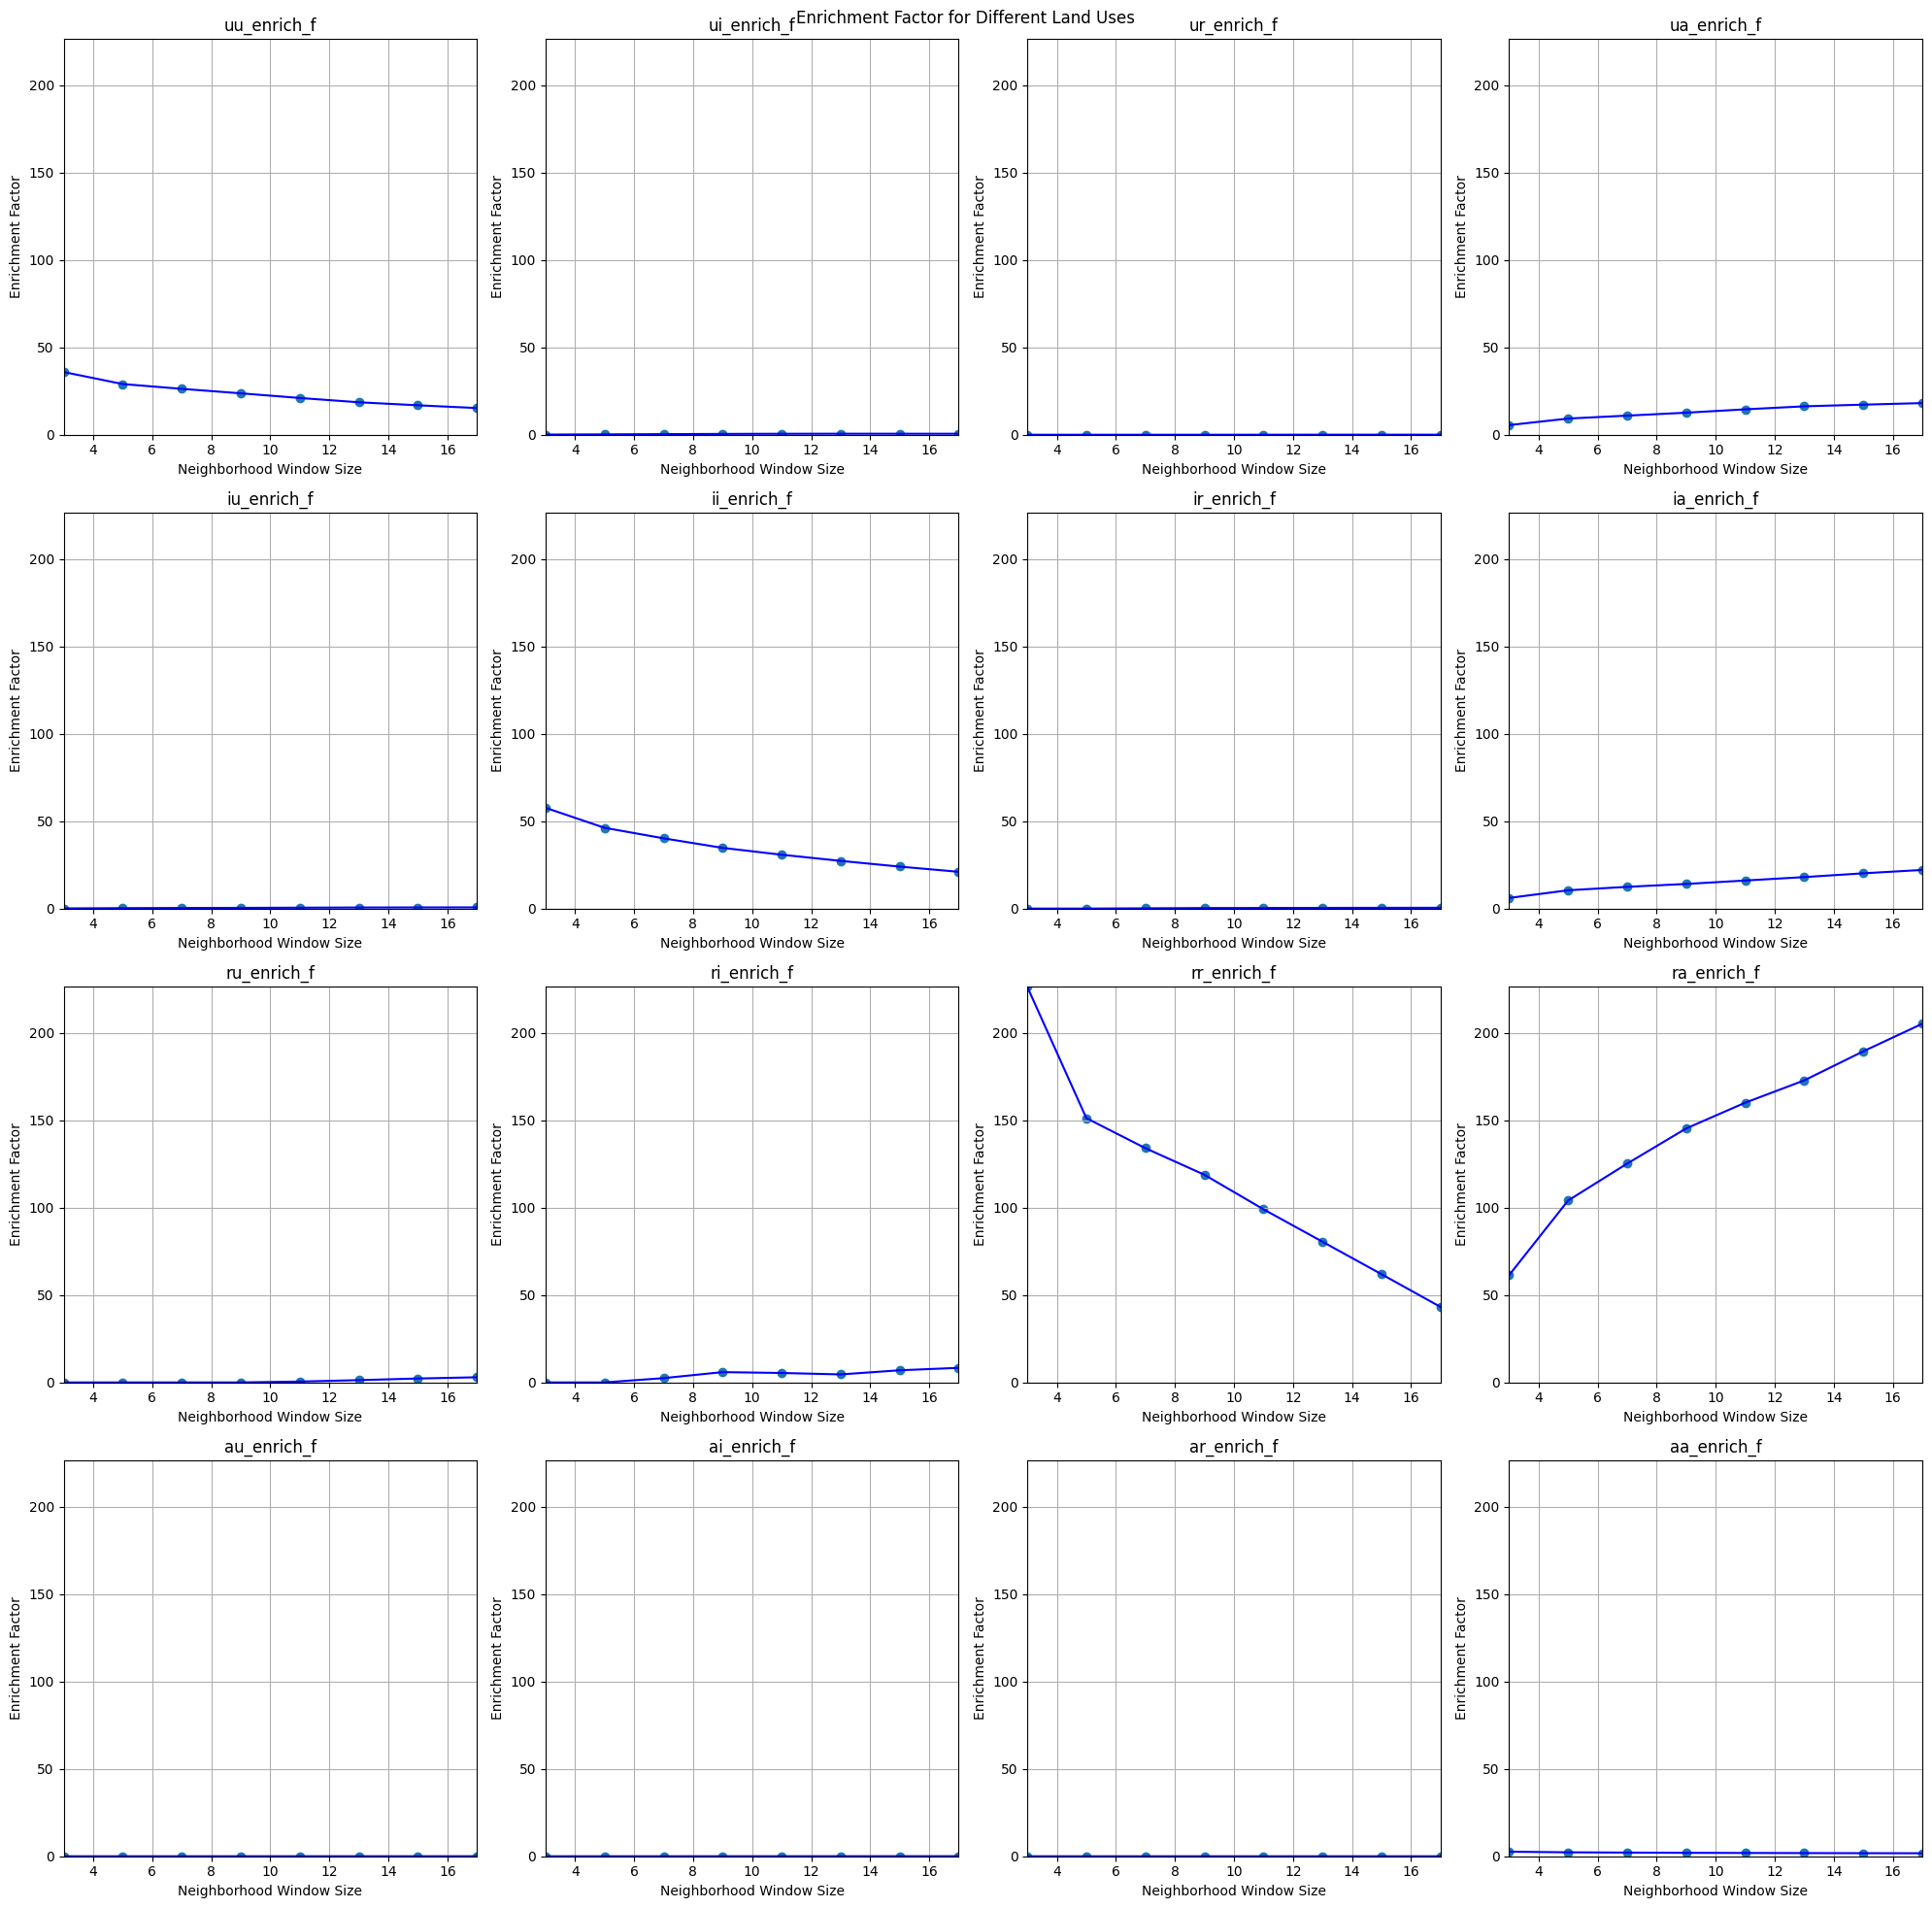

<Figure size 640x480 with 0 Axes>

In [ ]:
all_enrich_f = {
    'uu_enrich_f': uu_enrich_f,
    'ui_enrich_f': ui_enrich_f,
    'ur_enrich_f': ur_enrich_f,
    'ua_enrich_f': ua_enrich_f,
    'iu_enrich_f': iu_enrich_f,
    'ii_enrich_f': ii_enrich_f,
    'ir_enrich_f': ir_enrich_f,
    'ia_enrich_f': ia_enrich_f,
    'ru_enrich_f': ru_enrich_f,
    'ri_enrich_f': ri_enrich_f,
    'rr_enrich_f': rr_enrich_f,
    'ra_enrich_f': ra_enrich_f,
    'au_enrich_f': au_enrich_f,
    'ai_enrich_f': ai_enrich_f,
    'ar_enrich_f': ar_enrich_f,
    'aa_enrich_f': aa_enrich_f
}

plot_enrichment_factor(all_enrich_f, 'Enrichment Factor for Different Land Uses')

In [ ]:
log_enrich_f_dict = {}
for key, values in all_enrich_f.items():
    log_enrich_f_dict[key] = {k: np.log(v) for k, v in values.items()}

<ipython-input-31-89ac0afd34c5>:3: RuntimeWarning: divide by zero encountered in log
  log_enrich_f_dict[key] = {k: np.log(v) for k, v in values.items()}


نمودارهای زیر نشان دهنده لگاریتم شاخص غنی شدگی برای هر 16 حالت اثرگذاری کاربری ها بر یکدیگر میباشند

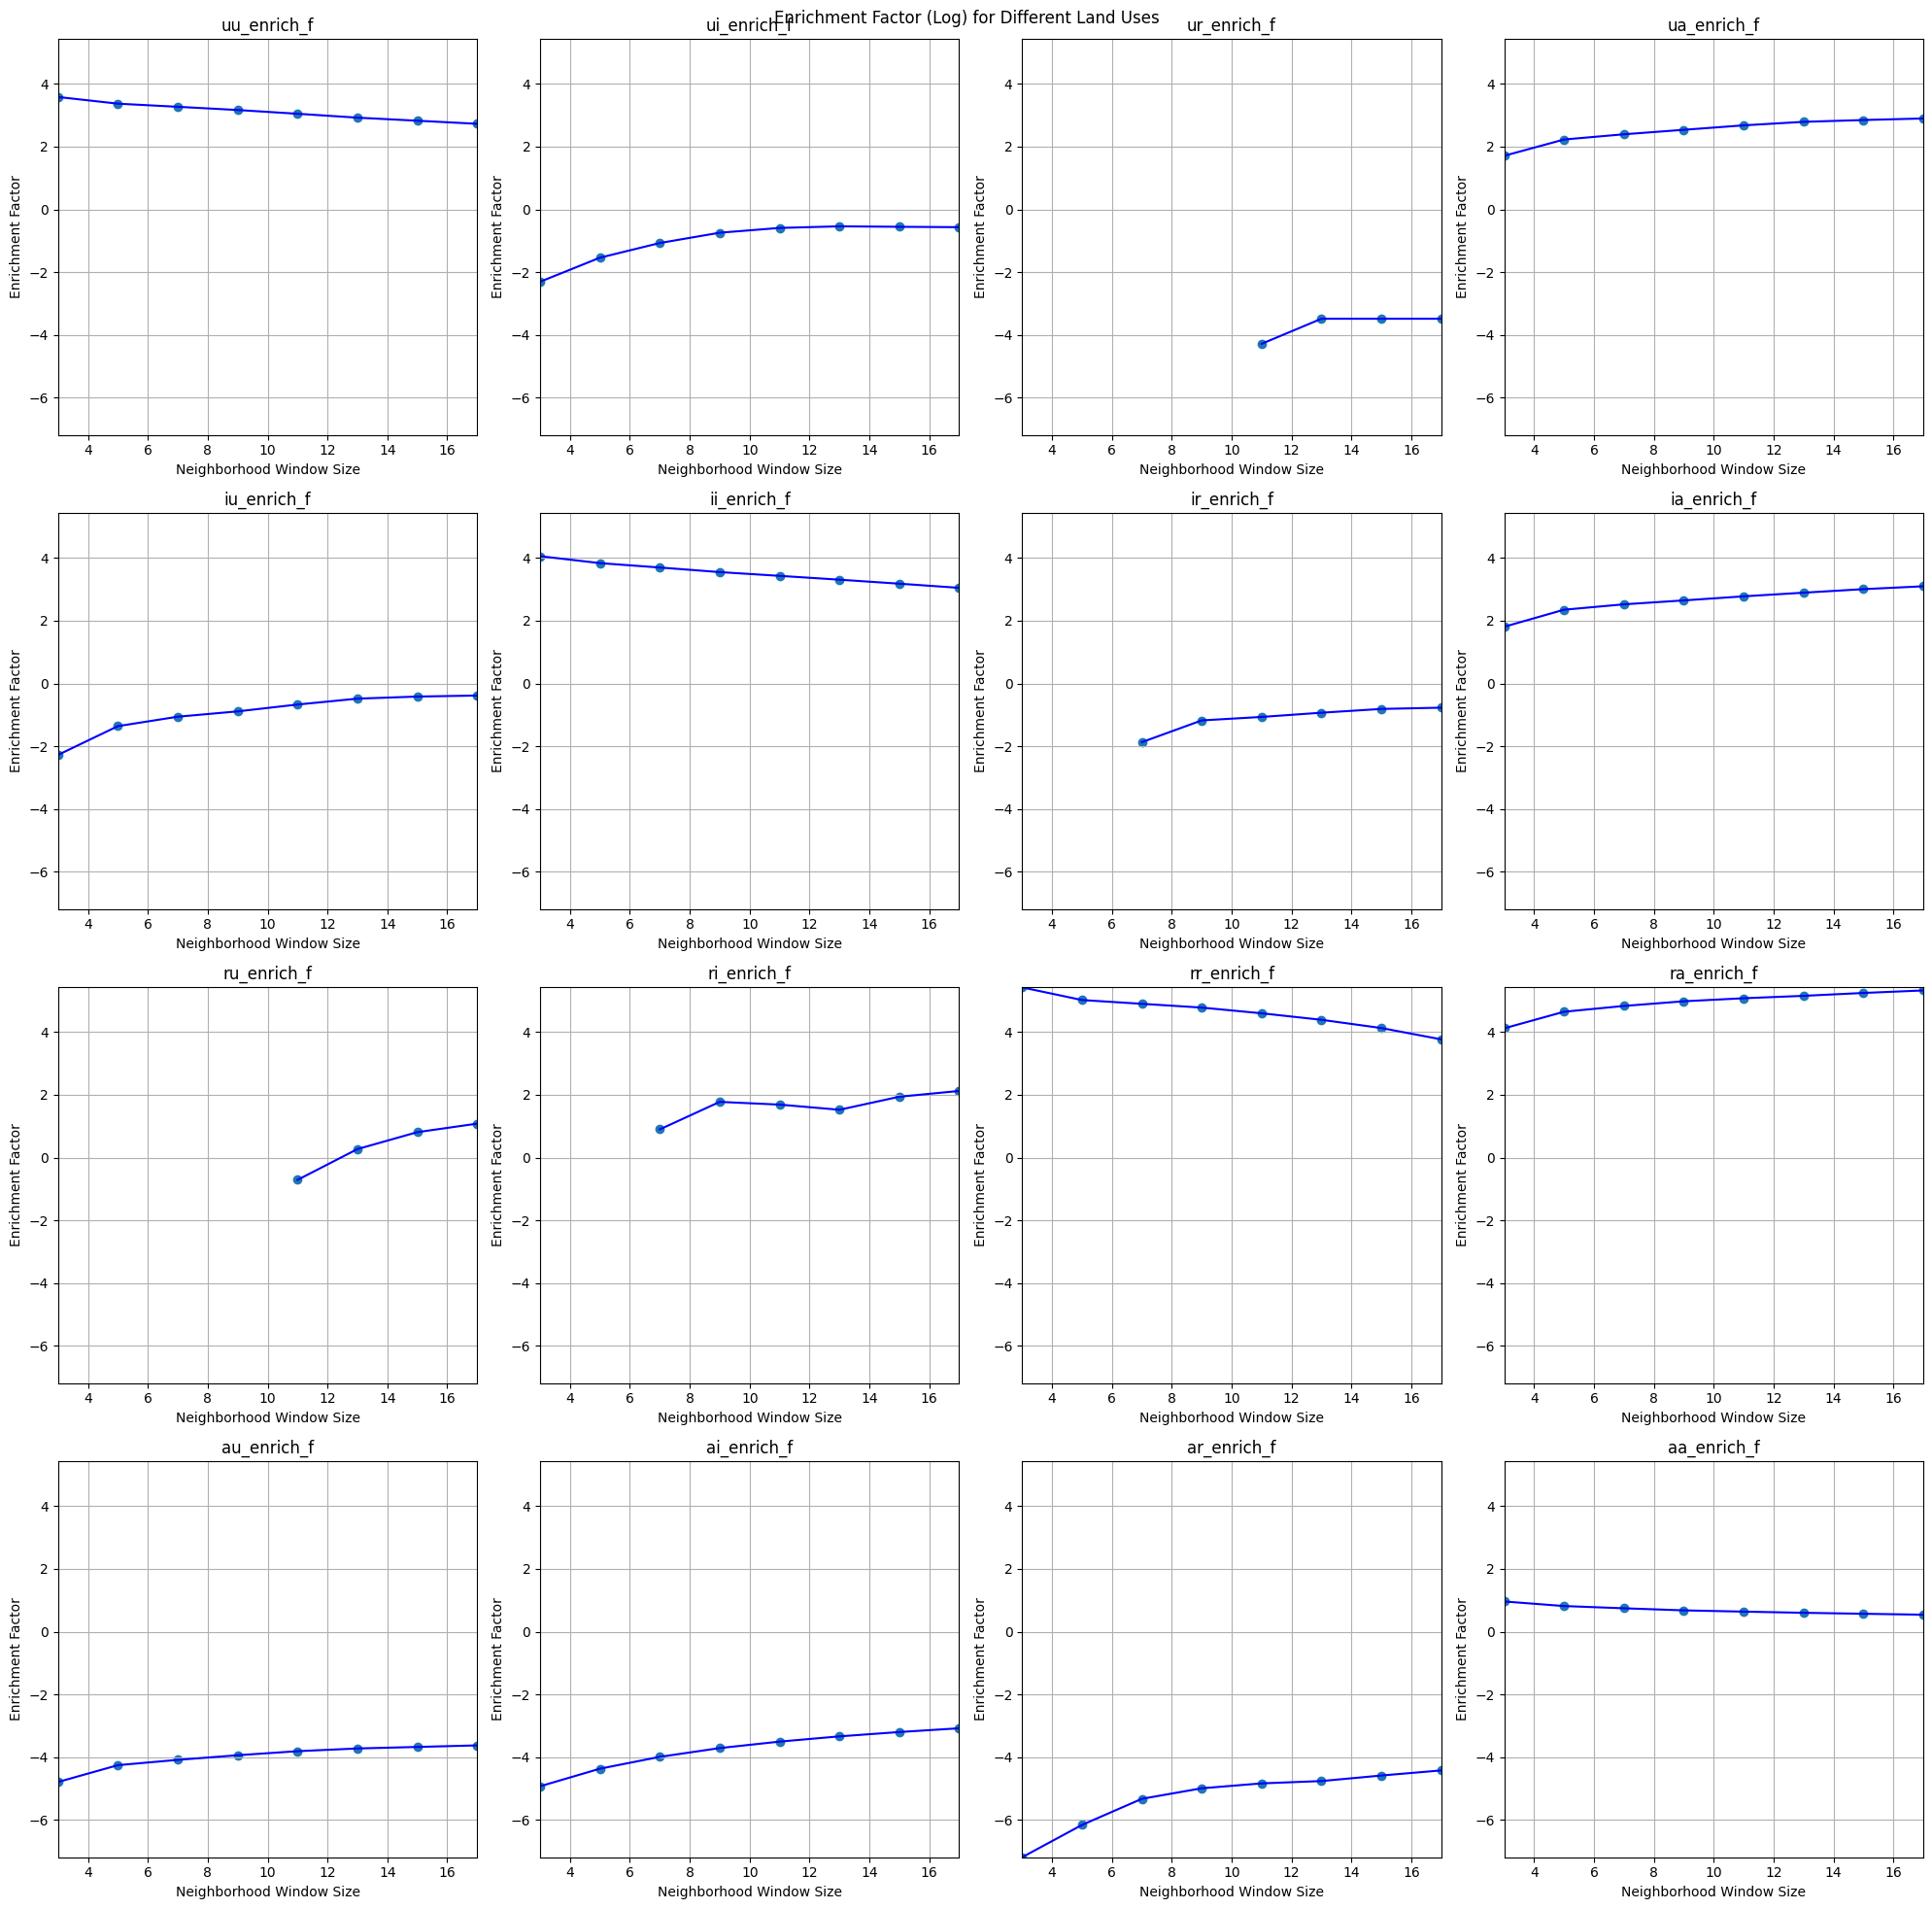

<Figure size 640x480 with 0 Axes>

In [ ]:
plot_enrichment_factor(log_enrich_f_dict, 'Enrichment Factor (Log) for Different Land Uses')

## **Circular Neighborhood**

##در  ادامه حالات مختلفی از همسایگی دایره ای اطراف یک پیکسل تعریف شده اند

در این قسمت، همسایگی دایره ای با گرفتن مختصات مرکز، شعاع داخلی و شعاع خارجی تعریف میشود. گرچه کد به درستی ران میشود، اما از خواسته ما که یک همسایگی با 8 رینگ مجزا و تولید شده به صورت خودکار اطراف هر پیکسل ورودی است، فاصله دارد

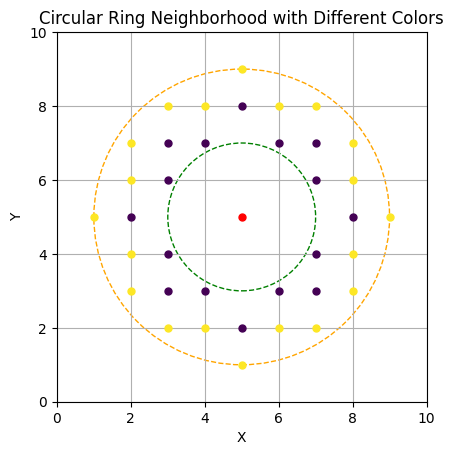

In [ ]:
def is_in_circular_ring(x, y, center_x, center_y, inner_radius, outer_radius):
    distance = np.sqrt((x - center_x)**2 + (y - center_y)**2)
    return inner_radius < distance <= outer_radius

def generate_circular_ring(center_x, center_y, inner_radius, outer_radius):
    ring_pixels = []
    for x in range(center_x - outer_radius, center_x + outer_radius + 1):
        for y in range(center_y - outer_radius, center_y + outer_radius + 1):
            if is_in_circular_ring(x, y, center_x, center_y, inner_radius, outer_radius):
                ring_pixels.append((x, y))
    return ring_pixels

center_x = 5
center_y = 5
inner_radius = 2
outer_radius = 4

circular_ring_pixels = generate_circular_ring(center_x, center_y, inner_radius, outer_radius)

fig, ax = plt.subplots()
ax.set_aspect('equal', adjustable='box')

ax.plot(center_x, center_y, marker='o', color='red', markersize=5, label='Central Pixel')

num_rings = outer_radius - inner_radius
colors = plt.cm.viridis(np.linspace(0, 1, num_rings))
for ring_index, color in zip(range(num_rings), colors):
    ring_pixels = generate_circular_ring(center_x, center_y, inner_radius + ring_index, inner_radius + ring_index + 1)
    for pixel in ring_pixels:
        ax.plot(pixel[0], pixel[1], marker='o', color=color, markersize=5)

inner_circle = plt.Circle((center_x, center_y), inner_radius, color='green', fill=False, linestyle='--', label='Inner Radius')
outer_circle = plt.Circle((center_x, center_y), outer_radius, color='orange', fill=False, linestyle='--', label='Outer Radius')

ax.add_artist(inner_circle)
ax.add_artist(outer_circle)

ax.set_xlim(center_x - outer_radius - 1, center_x + outer_radius + 1)
ax.set_ylim(center_y - outer_radius - 1, center_y + outer_radius + 1)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Circular Ring Neighborhood with Different Colors')
plt.grid(True)
plt.show()


In [ ]:
def circular_neighborhood(center_x, center_y, radius):
    neighborhood = []
    for i in range(-radius, radius + 1):
        for j in range(-radius, radius + 1):
            if i**2 + j**2 <= radius**2:
                neighborhood.append((center_x + i, center_y + j))
    return neighborhood

def generate_ring_sizes(num_rings):
    ring_sizes = []
    for i in range(1, num_rings + 1):
        ring_sizes.append(8 * i)
    return ring_sizes

def generate_circular_neighborhoods(center_x, center_y, num_rings):
    neighborhoods = []
    ring_sizes = generate_ring_sizes(num_rings)
    for ring_size in ring_sizes:
        neighborhood = circular_neighborhood(center_x, center_y, ring_size)
        neighborhoods.append(neighborhood)
    return neighborhoods

central_pixel_x = 10
central_pixel_y = 10
num_rings = 8

neighborhoods = generate_circular_neighborhoods(central_pixel_x, central_pixel_y, num_rings)

for i, neighborhood in enumerate(neighborhoods):
    print(f"Ring {i+1}: {len(neighborhood)} pixels")


Ring 1: 197 pixels
Ring 2: 797 pixels
Ring 3: 1793 pixels
Ring 4: 3209 pixels
Ring 5: 5025 pixels
Ring 6: 7213 pixels
Ring 7: 9845 pixels
Ring 8: 12853 pixels


In [ ]:
def calculate_ring_size(ring_number):
    return int(round(2 * np.pi * ring_number))

def circular_neighborhood(center_x, center_y, radius, exclude_radius=None):
    neighborhood = []
    if radius == 0:
        return neighborhood
    for i in range(-radius, radius + 1):
        for j in range(-radius, radius + 1):
            if i**2 + j**2 <= radius**2 and (exclude_radius is None or i**2 + j**2 > exclude_radius**2):
                neighborhood.append((center_x + i, center_y + j))
    return neighborhood

def generate_circular_neighborhoods(center_x, center_y, num_rings):
    neighborhoods = []
    for i in range(num_rings):
        radius = int(np.sqrt(calculate_ring_size(i+1) / np.pi))
        exclude_radius = int(np.sqrt(calculate_ring_size(i) / np.pi)) if i > 0 else None
        neighborhood = circular_neighborhood(center_x, center_y, radius, exclude_radius)
        neighborhoods.append(neighborhood)
    return neighborhoods

def plot_neighborhoods(neighborhoods):
    colors = ['r', 'g', 'b', 'c', 'm', 'y', 'k', 'orange']
    for i, neighborhood in enumerate(neighborhoods):
        if not neighborhood:
            continue
        xs, ys = zip(*neighborhood)
        plt.scatter(xs, ys, color=colors[i], label=f'Ring {i+1}')
    plt.xlabel('X-coordinate')
    plt.ylabel('Y-coordinate')
    plt.title('Circular Neighborhoods')
    plt.grid(True)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()

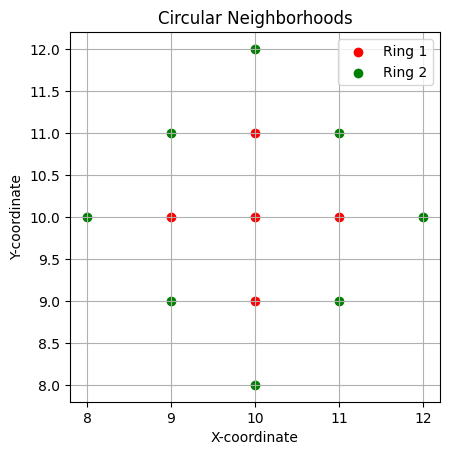

In [ ]:
neighborhoods = generate_circular_neighborhoods(10, 10, 4)
plot_neighborhoods(neighborhoods)

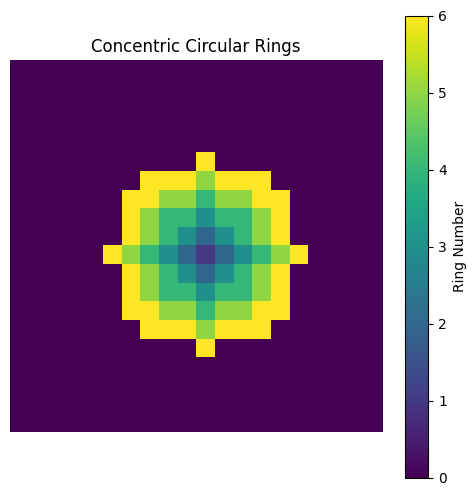

In [ ]:
def create_concentric_circles(size, center, num_rings):
    rings = np.zeros(size, dtype=int)

    rings[center] = 1

    for r in range(1, num_rings + 1):
        y, x = center
        for i in range(-r, r + 1):
            for j in range(-r, r + 1):
                if i**2 + j**2 <= r**2 and rings[y + i, x + j] == 0:
                    rings[y + i, x + j] = r + 1

    return rings

size = (20, 20)
center = (10, 10)
num_rings = 5

rings = create_concentric_circles(size, center, num_rings)

plt.figure(figsize=(6, 6))
plt.imshow(rings, cmap='viridis')
plt.title('Concentric Circular Rings')
plt.colorbar(label='Ring Number')
plt.axis('off')
plt.show()

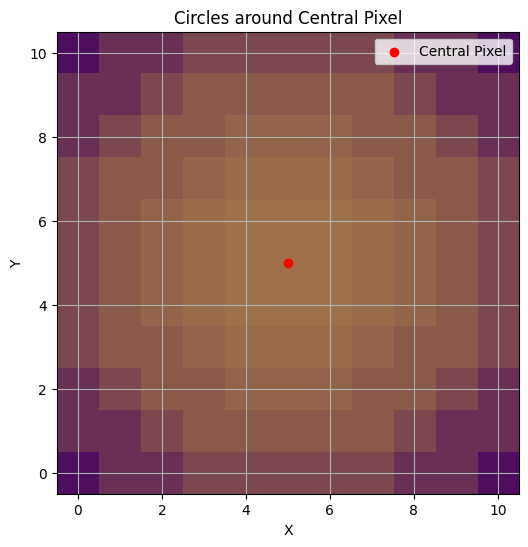

In [ ]:
def draw_circle(center, radius, grid_size):
    x, y = center
    grid = np.zeros((grid_size, grid_size))

    for i in range(grid_size):
        for j in range(grid_size):
            if (i - x) ** 2 + (j - y) ** 2 <= radius ** 2:
                grid[i, j] = 1

    return grid

def draw_circles_with_center(center, num_circles, grid_size):
    fig, ax = plt.subplots(figsize=(6, 6))

    for i in range(num_circles):
        circle_grid = draw_circle(center, 1.5 + i, grid_size)
        ax.imshow(circle_grid, cmap='viridis', alpha=0.3, extent=[-0.5, grid_size - 0.5, -0.5, grid_size - 0.5], label=f'Circle {i+1}')

    ax.scatter(center[1], center[0], color='red', zorder=10, label='Central Pixel')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Circles around Central Pixel')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(True)
    ax.legend()
    plt.show()

central_pixel = (5, 5)
num_circles = 8
grid_size = 11

draw_circles_with_center(central_pixel, num_circles, grid_size)


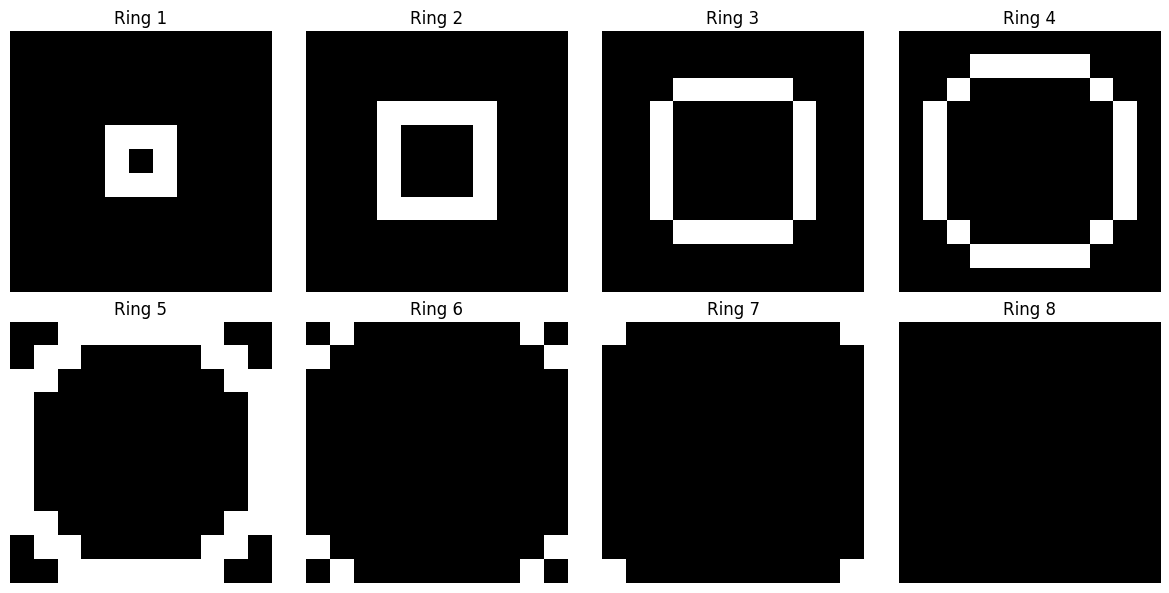

In [ ]:
def create_neighborhood(center, radius, image_shape):
    neighborhood = np.zeros(image_shape, dtype=bool)
    rows, cols = image_shape
    for i in range(rows):
        for j in range(cols):
            distance = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if radius - 0.5 <= distance < radius + 0.5:
                neighborhood[i, j] = True
    return neighborhood

def plot_neighborhood(neighborhoods):
    fig, axs = plt.subplots(2, 4, figsize=(12, 6))
    for i, ax in enumerate(axs.flat):
        ax.imshow(neighborhoods[i], cmap='gray')
        ax.set_title(f'Ring {i+1}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def main():
    central_pixel = (5, 5)
    image_shape = (11, 11)
    num_rings = 8

    neighborhoods = []
    for ring in range(num_rings):
        radius = ring + 1.5
        neighborhood = create_neighborhood(central_pixel, radius, image_shape)
        neighborhoods.append(neighborhood)

    plot_neighborhood(neighborhoods)

if __name__ == "__main__":
    main()

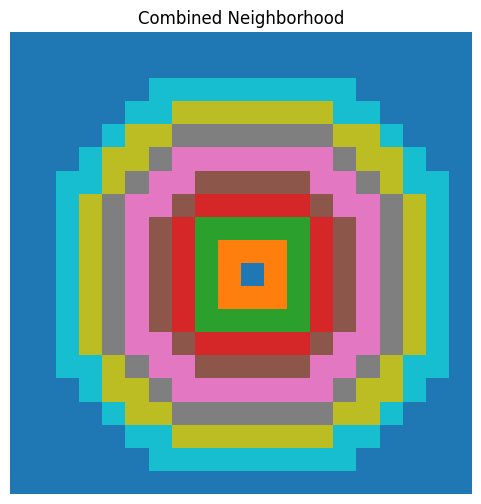

In [ ]:
def create_neighborhood(center, radius, image_shape):
    neighborhood = np.zeros(image_shape, dtype=int)
    rows, cols = image_shape
    for i in range(rows):
        for j in range(cols):
            distance = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if radius - 0.5 <= distance < radius + 0.5:
                neighborhood[i, j] = radius
    return neighborhood

def plot_neighborhood(neighborhoods):
    fig, ax = plt.subplots(figsize=(6, 6))
    combined_neighborhood = np.zeros_like(neighborhoods[0])
    for neighborhood in neighborhoods:
        combined_neighborhood += neighborhood
    ax.imshow(combined_neighborhood, cmap='tab10', interpolation='none')
    ax.set_title('Combined Neighborhood')
    ax.axis('off')
    plt.show()

def main():
    central_pixel = (10, 10)
    image_shape = (20, 20)
    num_rings = 8

    neighborhoods = []
    for ring in range(num_rings):
        radius = ring + 1.5
        neighborhood = create_neighborhood(central_pixel, radius, image_shape)
        neighborhoods.append(neighborhood)

    plot_neighborhood(neighborhoods)

if __name__ == "__main__":
    main()

این کد دایره‌های هم مرکزی را دور یک نقطه مرکزی ایجاد می‌کند. برای هر دایره، تمام پیکسل‌های داخل دایره پر می‌شوند و به هر پیکسل، شماره دایره‌ای که به آن تعلق دارد اختصاص می‌یابد. سپس این دایره‌ها به صورت یک نقشه رنگی نمایش داده می‌شوند که هر رنگ متناظر با یک دایره است.
این کد برای یک پیکسل با مختصات مشخص به عنوان ورودی نوشته شده است.

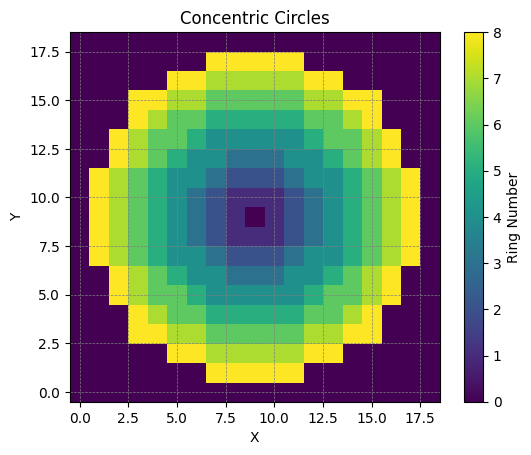

In [ ]:
def create_concentric_circles(center, num_rings=8):
    max_radius = num_rings + 1
    size = (2 * max_radius + 1, 2 * max_radius + 1)
    rings = np.zeros(size, dtype=int)

    center_x, center_y = center
    # Adjust center based on the size of the array
    adjusted_center_x = max_radius
    adjusted_center_y = max_radius

    for r in range(1, num_rings + 1):
        for i in range(-r, r + 1):
            for j in range(-r, r + 1):
                if adjusted_center_x + i >= 0 and adjusted_center_x + i < size[0] and adjusted_center_y + j >= 0 and adjusted_center_y + j < size[1]:
                    distance = np.sqrt(i**2 + j**2)
                    if r - 0.5 < distance <= r + 0.5:
                        rings[adjusted_center_x + i, adjusted_center_y + j] = r

    return rings

def plot_concentric_circles(rings):
    plt.imshow(rings, cmap='viridis', origin='lower')
    plt.colorbar(label='Ring Number')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Concentric Circles')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5, color='gray')
    plt.show()

center = (10, 10)
num_rings = 8
rings = create_concentric_circles(center, num_rings)
plot_concentric_circles(rings)


In [ ]:
def calculate_total_pixels(num_rings):
    total_pixels = {ring: 0 for ring in range(1, num_rings + 1)}
    for r in range(1, num_rings + 1):
        for i in range(-r, r + 1):
            for j in range(-r, r + 1):
                distance = np.sqrt(i**2 + j**2)
                if r - 0.5 < distance <= r + 0.5:
                    total_pixels[r] += 1
    return total_pixels

def count_neighborhood_circ(binary_map, landuse_map, target_value, num_rings=8):
    size = binary_map.shape
    counts = {ring: [] for ring in range(1, num_rings + 1)}
    total_pixels = calculate_total_pixels(num_rings)

    for center_x in range(size[0]):
        for center_y in range(size[1]):
            if binary_map[center_x, center_y] == 1:
                for r in range(1, num_rings + 1):
                    ring_count = 0
                    for i in range(-r, r + 1):
                        for j in range(-r, r + 1):
                            new_x, new_y = center_x + i, center_y + j
                            if new_x >= 0 and new_x < size[0] and new_y >= 0 and new_y < size[1]:
                                distance = np.sqrt(i**2 + j**2)
                                if r - 0.5 < distance <= r + 0.5:
                                    if landuse_map[new_x, new_y] == target_value:
                                        ring_count += 1
                    counts[r].append(ring_count)

    return counts, total_pixels

In [ ]:
urban_test, total_pixels = count_neighborhood_circ(changed_to_urban, lu2_data, 1)

In [ ]:
def enrichment_factor_circ(lu_neighbors_count, lu_counts, land_use, total_pixels_circ, total_pixels_g):
    local_f = {}

    # Calculate Local F using the number of pixels in each ring from total_pixels
    for ring, counts in lu_neighbors_count.items():
        local_f[ring] = [count / total_pixels_circ[ring] for count in counts]

    # Calculate Global F
    global_f = lu_counts[land_use] / total_pixels_g

    # Calculate Enrichment Factor
    for ring, counts in local_f.items():
        local_f[ring] = [count / global_f for count in counts]

    # Average of the Enrichment Factors for every pixel corresponding to the same neighborhood
    enrichment_f = {}
    for ring, counts in local_f.items():
        enrichment_f[ring] = sum(counts) / len(counts)

    return enrichment_f

In [ ]:
urban_ef = enrichment_factor_circ(urban_test, land_use_counts2, 'Urban', total_pixels, total_pixels2)

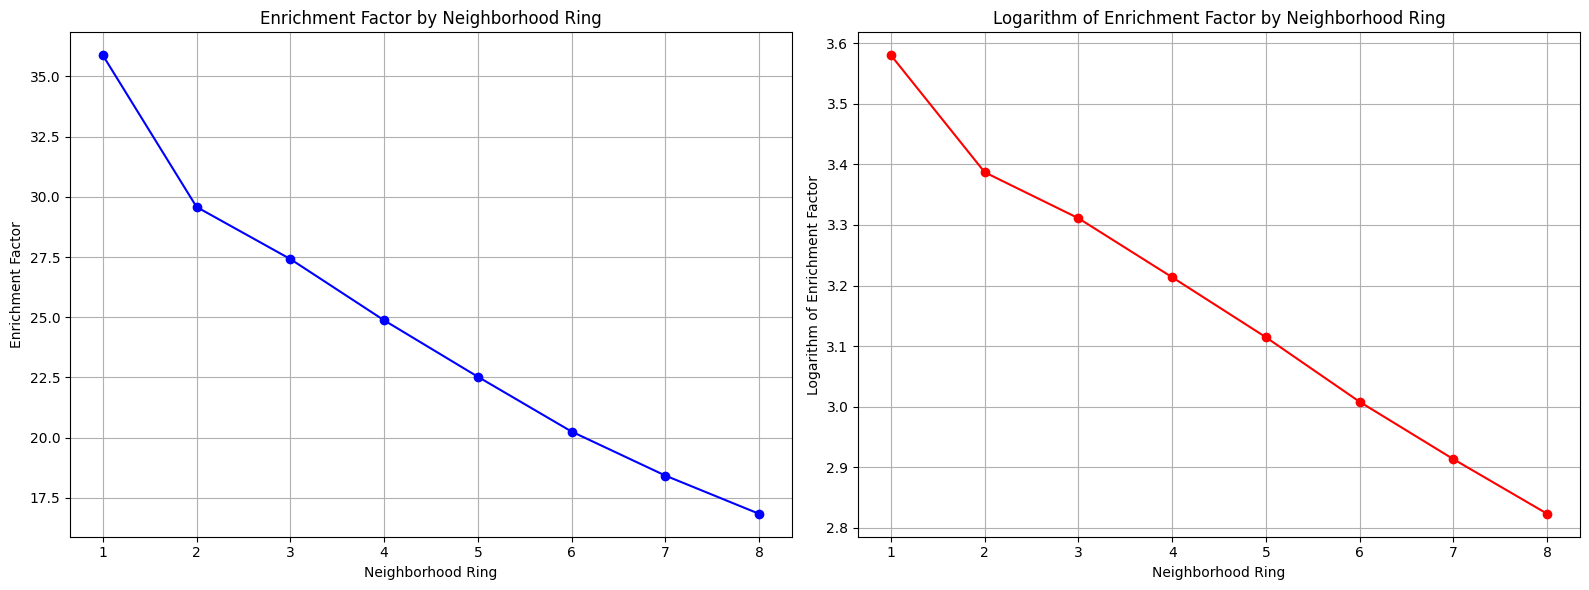

In [ ]:
rings = sorted(urban_ef.keys())
enrichment_factors = [urban_ef[ring] for ring in rings]

log_enrichment_factors = [np.log(factor) if factor > 0 else float('-inf') for factor in enrichment_factors]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(rings, enrichment_factors, marker='o', linestyle='-', color='b')
ax1.set_xlabel('Neighborhood Ring')
ax1.set_ylabel('Enrichment Factor')
ax1.set_title('Enrichment Factor by Neighborhood Ring')
ax1.grid(True)

ax2.plot(rings, log_enrichment_factors, marker='o', linestyle='-', color='r')
ax2.set_xlabel('Neighborhood Ring')
ax2.set_ylabel('Logarithm of Enrichment Factor')
ax2.set_title('Logarithm of Enrichment Factor by Neighborhood Ring')
ax2.grid(True)

plt.tight_layout()
plt.show()

این کد تعداد تکرار پیکسل مربوط به هر کاربری را در هر همسایگی مدور دور هر پیکسل با مقدار ۱ در آرایه‌ی داده شده را محاسبه می‌کند و آن را در یک دیکشنری ذخیره می‌کند.

از این تابع جهت شمارش تعداد کل پیکسل های موجود در یک رینگ از همسایگی دایره ای تعریف شده استفاده می شود. نتیجه به صورت یک دیکشنری حاوی شماره رینگ و تعداد پیکسل های مربوط به آن ارائه شده است

اکنون تعداد کل پیکسل های مربوط به هر کاربری در هر نقشه به دست آمده از کاربریهای تغییر یافته با مقایسه دو نقشه موجود، شمرده شده و ذخیره میشوند تا در ادامه جهت محاسبه  شاخص غنی شدگی استفاده شوند

In [ ]:
uu_neighbors_circ = count_neighborhood_circ(changed_to_urban, lu2_data, 1)[0]
ui_neighbors_circ = count_neighborhood_circ(changed_to_urban, lu2_data, 2)[0]
ur_neighbors_circ = count_neighborhood_circ(changed_to_urban, lu2_data, 3)[0]
ua_neighbors_circ = count_neighborhood_circ(changed_to_urban, lu2_data, 4)[0]

iu_neighbors_circ = count_neighborhood_circ(changed_to_industrial, lu2_data, 1)[0]
ii_neighbors_circ = count_neighborhood_circ(changed_to_industrial, lu2_data, 2)[0]
ir_neighbors_circ = count_neighborhood_circ(changed_to_industrial, lu2_data, 3)[0]
ia_neighbors_circ = count_neighborhood_circ(changed_to_industrial, lu2_data, 4)[0]

ru_neighbors_circ = count_neighborhood_circ(changed_to_rural, lu2_data, 1)[0]
ri_neighbors_circ = count_neighborhood_circ(changed_to_rural, lu2_data, 2)[0]
rr_neighbors_circ = count_neighborhood_circ(changed_to_rural, lu2_data, 3)[0]
ra_neighbors_circ = count_neighborhood_circ(changed_to_rural, lu2_data, 4)[0]

au_neighbors_circ = count_neighborhood_circ(changed_to_agricultural, lu2_data, 1)[0]
ai_neighbors_circ = count_neighborhood_circ(changed_to_agricultural, lu2_data, 2)[0]
ar_neighbors_circ = count_neighborhood_circ(changed_to_agricultural, lu2_data, 3)[0]
aa_neighbors_circ = count_neighborhood_circ(changed_to_agricultural, lu2_data, 4)[0]

اکنون تابعی جهت محاسبه شاخص غنی شدگی اما این بار بر اساس تعداد پیکسل های هر رینگ در همسایگی دایره ای تعریف شده نوشته میشود

در ادامه این شاخص برای هر 16 حالت محاسبه شده و نمودار آن ها رسم شده اند

In [ ]:
uu_enrich_f_circ = enrichment_factor_circ(uu_neighbors_circ, land_use_counts2, 'Urban', total_pixels, total_pixels2)
ui_enrich_f_circ = enrichment_factor_circ(ui_neighbors_circ, land_use_counts2, 'Urban', total_pixels, total_pixels2)
ur_enrich_f_circ = enrichment_factor_circ(ur_neighbors_circ, land_use_counts2, 'Urban', total_pixels, total_pixels2)
ua_enrich_f_circ = enrichment_factor_circ(ua_neighbors_circ, land_use_counts2, 'Urban', total_pixels, total_pixels2)

iu_enrich_f_circ = enrichment_factor_circ(iu_neighbors_circ, land_use_counts2, 'Industrial', total_pixels, total_pixels2)
ii_enrich_f_circ = enrichment_factor_circ(ii_neighbors_circ, land_use_counts2, 'Industrial', total_pixels, total_pixels2)
ir_enrich_f_circ = enrichment_factor_circ(ir_neighbors_circ, land_use_counts2, 'Industrial', total_pixels, total_pixels2)
ia_enrich_f_circ = enrichment_factor_circ(ia_neighbors_circ, land_use_counts2, 'Industrial', total_pixels, total_pixels2)

ru_enrich_f_circ = enrichment_factor_circ(ru_neighbors_circ, land_use_counts2, 'Rural', total_pixels, total_pixels2)
ri_enrich_f_circ = enrichment_factor_circ(ri_neighbors_circ, land_use_counts2, 'Rural', total_pixels, total_pixels2)
rr_enrich_f_circ = enrichment_factor_circ(rr_neighbors_circ, land_use_counts2, 'Rural', total_pixels, total_pixels2)
ra_enrich_f_circ = enrichment_factor_circ(ra_neighbors_circ, land_use_counts2, 'Rural', total_pixels, total_pixels2)

au_enrich_f_circ = enrichment_factor_circ(au_neighbors_circ, land_use_counts2, 'Agricultural', total_pixels, total_pixels2)
ai_enrich_f_circ = enrichment_factor_circ(ai_neighbors_circ, land_use_counts2, 'Agricultural', total_pixels, total_pixels2)
ar_enrich_f_circ = enrichment_factor_circ(ar_neighbors_circ, land_use_counts2, 'Agricultural', total_pixels, total_pixels2)
aa_enrich_f_circ = enrichment_factor_circ(aa_neighbors_circ, land_use_counts2, 'Agricultural', total_pixels, total_pixels2)

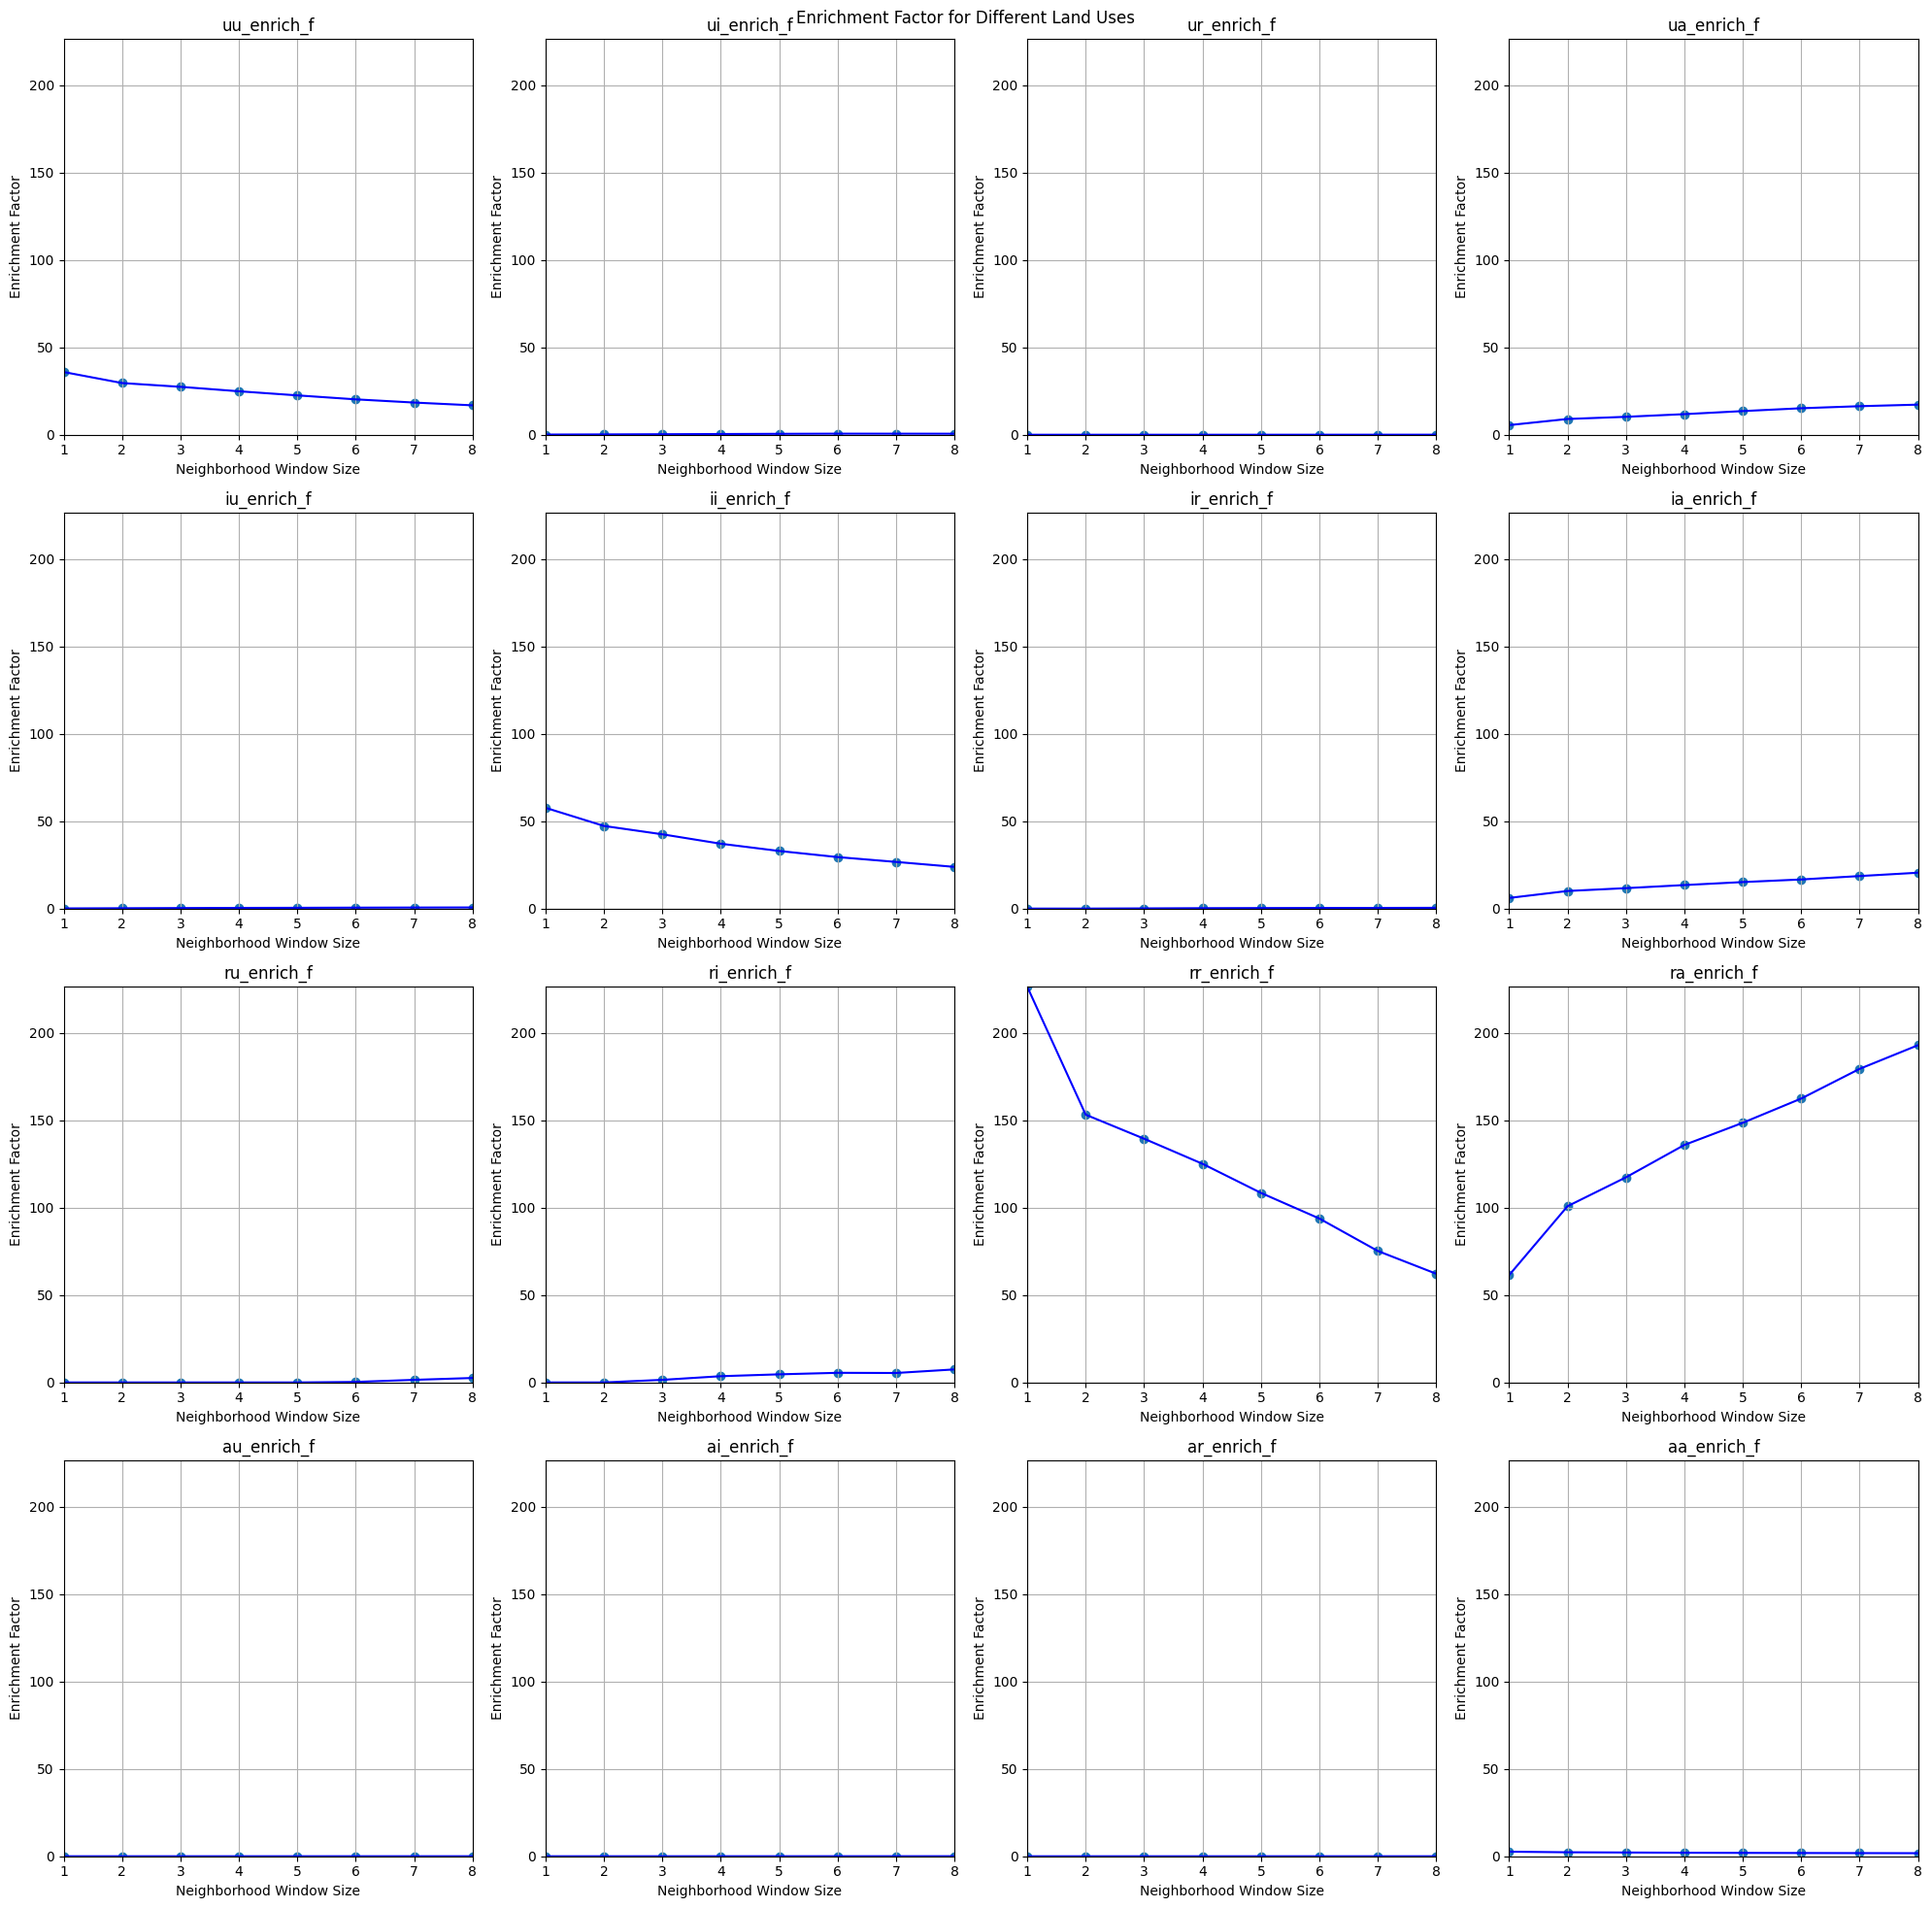

<Figure size 640x480 with 0 Axes>

In [ ]:
all_enrich_f_circ = {
    'uu_enrich_f': uu_enrich_f_circ,
    'ui_enrich_f': ui_enrich_f_circ,
    'ur_enrich_f': ur_enrich_f_circ,
    'ua_enrich_f': ua_enrich_f_circ,
    'iu_enrich_f': iu_enrich_f_circ,
    'ii_enrich_f': ii_enrich_f_circ,
    'ir_enrich_f': ir_enrich_f_circ,
    'ia_enrich_f': ia_enrich_f_circ,
    'ru_enrich_f': ru_enrich_f_circ,
    'ri_enrich_f': ri_enrich_f_circ,
    'rr_enrich_f': rr_enrich_f_circ,
    'ra_enrich_f': ra_enrich_f_circ,
    'au_enrich_f': au_enrich_f_circ,
    'ai_enrich_f': ai_enrich_f_circ,
    'ar_enrich_f': ar_enrich_f_circ,
    'aa_enrich_f': aa_enrich_f_circ
}

plot_enrichment_factor(all_enrich_f_circ, 'Enrichment Factor for Different Land Uses')

با گرفتن لگاریتم از مقادیر به دست آمده از تابع قبلی، نمودارهای لگاریتم شاخص غنی شدگی هر 16 حالت در ادامه رسم شده اند

In [ ]:
log_enrich_f_circ_dict = {}
for key, values in all_enrich_f_circ.items():
    log_enrich_f_circ_dict[key] = {k: np.log(v) for k, v in values.items()}

<ipython-input-89-0000988861f4>:3: RuntimeWarning: divide by zero encountered in log
  log_enrich_f_circ_dict[key] = {k: np.log(v) for k, v in values.items()}


In [ ]:
log_enrich_f_circ_dict.items()

dict_items([('uu_enrich_f', {1: 3.5802322422703514, 2: 3.38704218061349, 3: 3.3111051485187195, 4: 3.2136817350315043, 5: 3.1146440345619677, 6: 3.008029559579981, 7: 2.9133552039462827, 8: 2.823206200942861}), ('ui_enrich_f', {1: -2.3060854415681886, 2: -1.6929809686817796, 3: -1.2334486393033395, 4: -0.9102216294321468, 5: -0.655737626389961, 6: -0.4890081643558446, 7: -0.506663099594566, 8: -0.5315677787746417}), ('ur_enrich_f', {1: -inf, 2: -inf, 3: -inf, 4: -inf, 5: -5.025185478856984, 6: -4.1778876184697795, 7: -3.7078839892240443, 8: -3.4847404379098346}), ('ua_enrich_f', {1: 1.7068265586913256, 2: 2.19883932942885, 3: 2.3278964416584533, 4: 2.4667155858038594, 5: 2.6052757829266424, 6: 2.7186044682336465, 7: 2.7933118330688913, 8: 2.8463164731556065}), ('iu_enrich_f', {1: -2.275574910680259, 2: -1.5824277301203138, 3: -1.1769626220121492, 4: -0.9455202678832445, 5: -0.8037583761222061, 6: -0.6317355715288262, 7: -0.5220366542724015, 8: -0.4429934469319491}), ('ii_enrich_f', {1:

In [ ]:
log_enrich_f_circ_dict["ur_enrich_f"][5]

-5.025185478856984

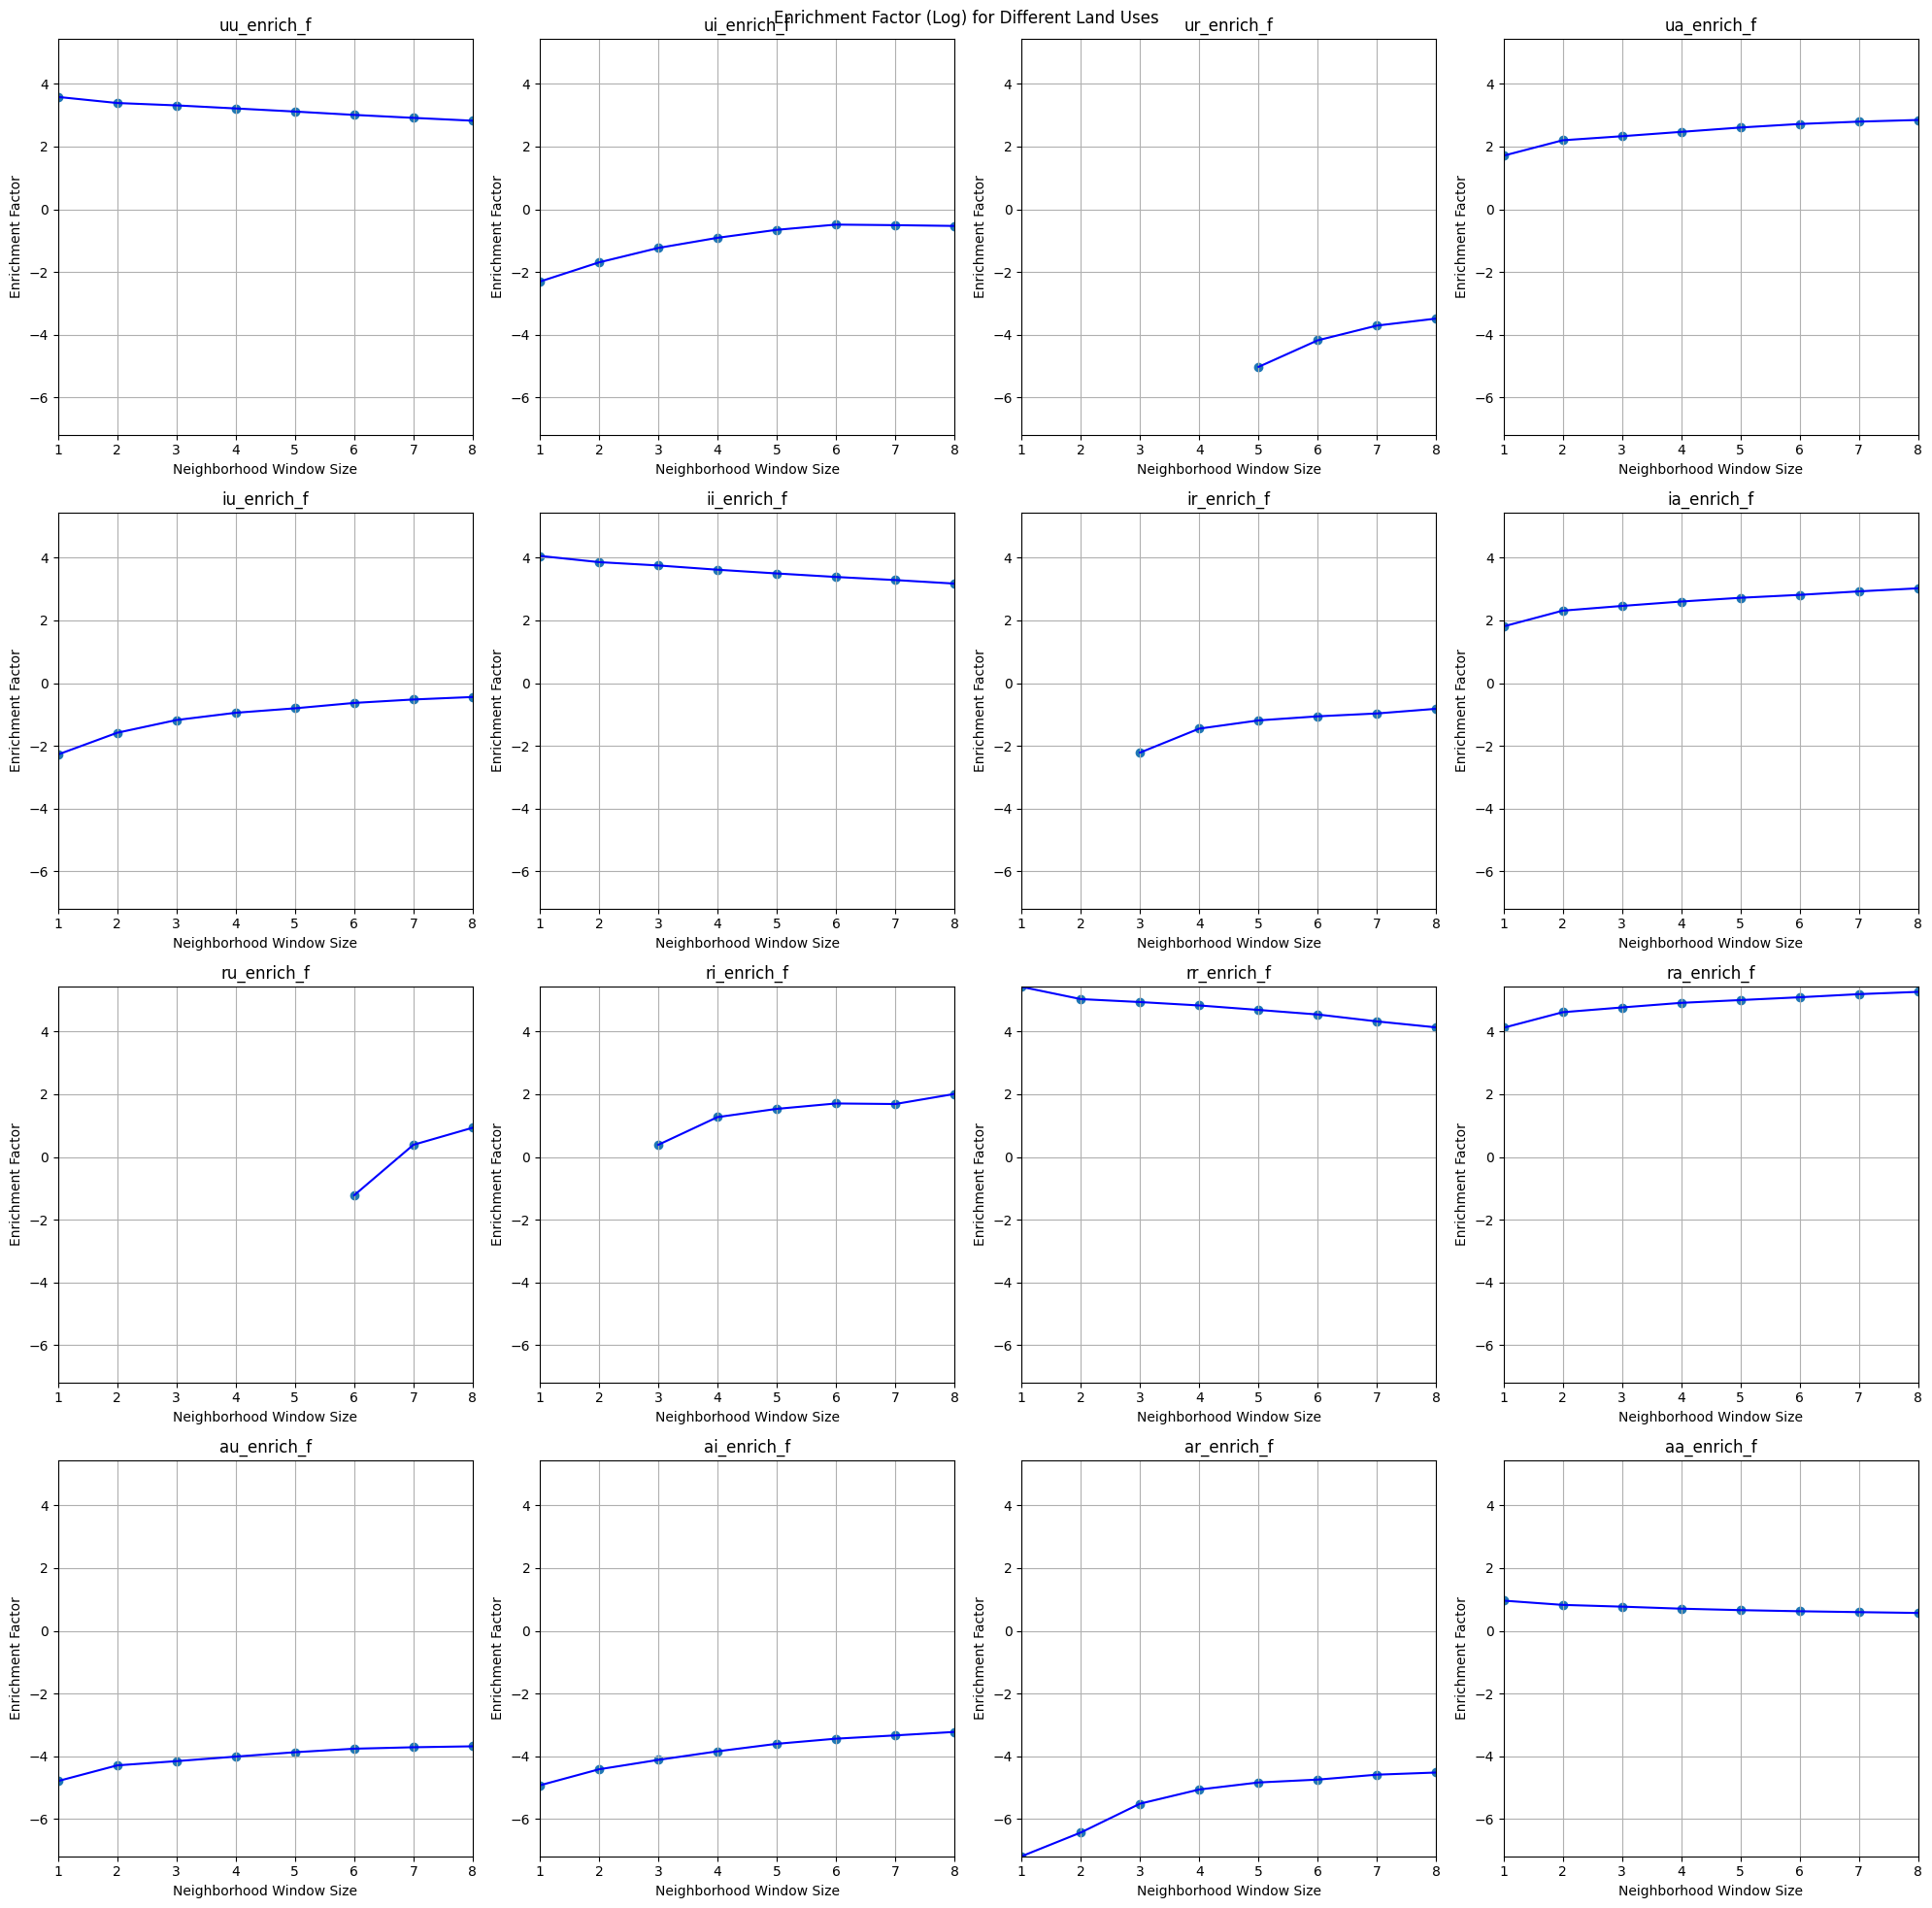

<Figure size 640x480 with 0 Axes>

In [ ]:
plot_enrichment_factor(log_enrich_f_circ_dict, 'Enrichment Factor (Log) for Different Land Uses')

## برازش نمودار به قسمتهای بدون مقدار

نمودار مربوط به شهری-روستایی را انتخاب میکنیم و مقادیر عددی آن را از مقادیر بینهایت موجود در لیست آن جدا میکنیم تا رینگهای دارای مقدار را از آنهایی که مقدار ندارند تفکیک کنیم

In [ ]:
log_circ_ur_list = []
for i in range(1, 9):
    if i in log_enrich_f_circ_dict["ur_enrich_f"] and log_enrich_f_circ_dict["ur_enrich_f"][i] > -100000 :
        log_circ_ur_list.append(log_enrich_f_circ_dict["ur_enrich_f"][i])

In [ ]:
log_circ_ur_list

[-5.025185478856984,
 -4.1778876184697795,
 -3.7078839892240443,
 -3.4847404379098346]

ابتدا این کار را به صورت دستی انجام میدهیم تا از جواب دادن روش مورد نظر اطمینان حاصل کنیم. رینگهای دارای مقدار را به همراه مقادیرشان وارد میکنیم و یک تابع لگاریتمی را به آن ها برازش میدهیم

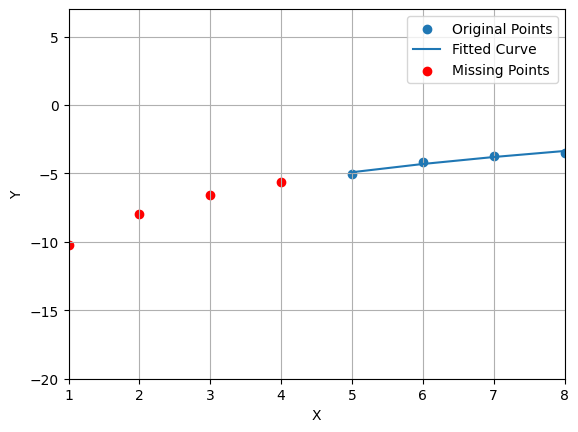

In [ ]:
x_data = np.array([5, 6, 7, 8])
y_data = log_circ_ur_list

def logarithmic_func(x, a, b):
    return a * np.log(x) + b

params, covariance = curve_fit(logarithmic_func, x_data, y_data)

missing_points_x = np.arange(1, x_data[0])
missing_points_y = logarithmic_func(missing_points_x, *params)

plt.scatter(x_data, y_data, label='Original Points')

plt.plot(x_data, logarithmic_func(x_data, *params), label='Fitted Curve')

plt.scatter(missing_points_x, missing_points_y, color='red', label='Missing Points')
plt.xlim(1, x_data[-1])

plt.ylim(-20, 7)

plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

مشاهده میشود که نتیجه مطلوب میباشد. بنابراین به جای وارد کردن مقادیر به صورت دستی، یک تابع تعریف  میکنیم که تنها ورودی آن، دیکشنری حاوی تمامی مقادیر لگاریتمهای شاخص غنی شدگی به تفکیک رینگ ها میباشد

In [ ]:
def fitness(dict):
    def logarithmic_func(x, a, b):
        return a * np.log(x) + b

    fig, axes = plt.subplots(4, 4, figsize=(16, 16))
    axes = axes.flatten()

    for idx, (key, ax) in enumerate(zip(dict.keys(), axes)):
        x_data = []
        y_data = []
        for i in range(1, 9):
            if i in dict[key] and dict[key][i] > -100000:
                x_data.append(i)
                y_data.append(dict[key][i])

        params, covariance = curve_fit(logarithmic_func, x_data, y_data)

        missing_points_x = np.arange(1, x_data[0])
        missing_points_y = logarithmic_func(missing_points_x, *params)

        ax.scatter(x_data, y_data, label='Original Points')
        ax.plot(x_data, logarithmic_func(x_data, *params), label='Fitted Curve')
        ax.scatter(missing_points_x, missing_points_y, color='red', label='Missing Points')
        ax.set_xlim(1, x_data[-1])
        ax.set_ylim(-20, 7)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.legend()
        ax.grid(True)

        ax.set_title(f"Graph {idx+1}: {key}")


    for ax in axes[len(dict):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

مشاهده میشود که تمامی رینگهایی که مقدار نداشتند، اکنون با برازش مقادیر به دست آمده از رینگ های بعدی حاوی مقدار هستند

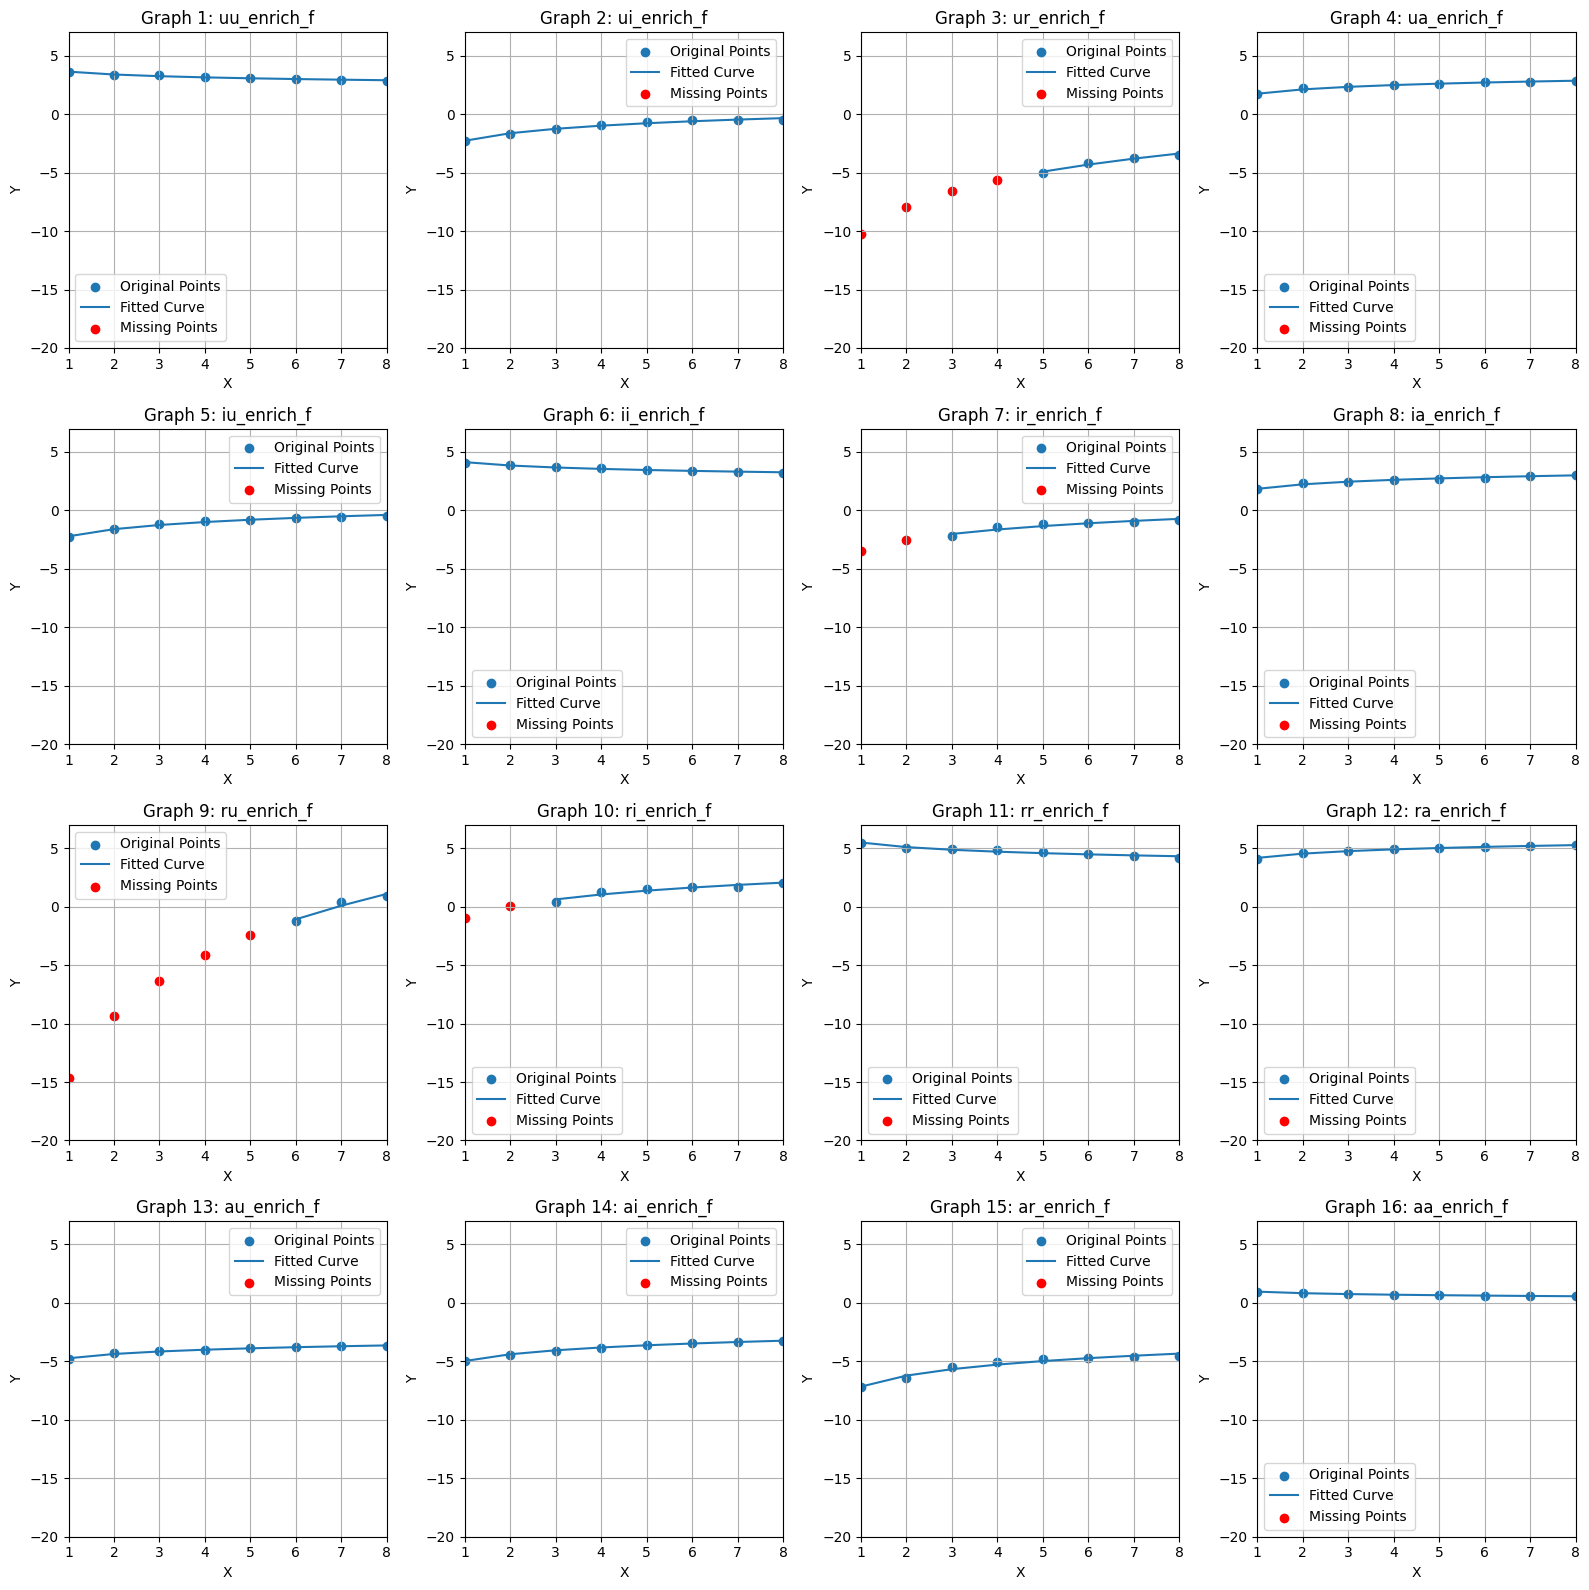

In [ ]:
fitness(log_enrich_f_circ_dict)